This notebook implements the Tidy3D script necessary to simulate the whole optical system (from input to output plane). 
It initializes the simulation domain by importing the necessary data, which consists of:
1) The input field, defined after the facet-expander transition
2) The first and second metasurface phase masks

In order to avoid simulating large empty spaces, which would be expensive, we exploit custom sources and projection monitors.

The input field, which represents the field after the fiber-expander transition, is propagated up to a certain distance before MS1. This is achieved through far-field projection monitors.
The projected field is then used to define a custom field source before MS1; the field after MS1 is then recorded and projected in the far-field again. This second projection defines the field before MS2.
The field after MS2 is recorded and projected for the last time. This last step is used to compute the field on the output plane.

In [1]:
import tidy3d as td
from tidy3d import web
from tidy3d import SimulationData

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 7)

In [101]:
#all dimensions in [um]
lda0 = 1.55
lambda0 = lda0
freq0 = td.C_0 / lda0
fwidth = freq0 / 10

###################
#MATERIALS
n_si = 3.45 #silicon refractive index
si = td.Medium(permittivity = n_si ** 2)
n_sio2 = 1.444
sio2 = td.Medium(permittivity = n_sio2 ** 2)
n_air = 1.0 #air refractive index
air = td.Medium(permittivity = n_air ** 2)
###################

###################
#UNIT-CELL RELATED
P = 0.7 #unit cell pitch [um]
unit_cell_pitch = P
h = 0.9 #pillar height [um]
###################

###################
#PROPAGATION DISTANCES
d0 = 195 #[um]
d1 = 129 #[um]
d2 = d0 #[um]
###################

###################
#SPATIAL GRIDs
#full grid
Nx = 1025 #pixels per dimension
Ny = Nx

#quadrant
nx = (Nx - 1) // 2 #indices without 0-axes (= #512)
ny = (Ny - 1) // 2
dof = 2*((nx + 1)**2) #number of degrees of freedom per metasurface (one quadrant)
S = Nx * Ny

size_x = unit_cell_pitch * Nx #actual physical size
size_y = unit_cell_pitch * Ny

xs = np.arange(-Nx//2+1, Nx//2+1) * (size_x / Nx)
ys = np.arange(-Ny//2+1, Ny//2+1) * (size_y / Ny)
X, Y = np.meshgrid(xs, ys)
rho = np.sqrt(X**2 + Y**2)

try:
    assert(len(xs) == Nx)
    assert(len(ys) == Ny)
    assert(xs[0] == xs[-1]*-1)
    assert(ys[0] == ys[-1]*-1)
    assert(xs[nx]==0)
    assert(ys[ny]==0)
    assert(np.abs(np.abs(xs[1]-xs[0]) - unit_cell_pitch) < 1e-12)
except:
    raise ValueError("Error while setting up the spatial grid.")

#SIMULATION GRID
fibre_cladding_diameter = 125 #[um]
max_available_diameter = 80 #[um] - maximum available metasurface footprint
max_sim_size = 90 #[um] maximum simulation size
max_sim_radius = max_sim_size / 2
sim_x_size = max_sim_size #x dimension [um] slightly larger than the metasurface footprint
sim_y_size = sim_x_size #y dimension [um]
sim_z_size = h + lda0 + 0.4

sim_mask = np.zeros((Nx, Ny),dtype=int)
for i in range(Nx):
    for j in range(Ny):
        if np.abs(X[i,j]) < sim_x_size/2 and np.abs(Y[i,j]) < sim_y_size/2:
            sim_mask[i,j] = 1
        else:
            sim_mask[i,j] = 0

Nx_sim = int(np.sum(sim_mask, axis=1).max())

Ny_sim = Nx_sim
nx_sim = (Nx_sim - 1) // 2 #indices without 0-axes (=#512)
ny_sim = (Ny_sim - 1) // 2 
xs_sim = np.arange(-Nx_sim//2+1, Nx_sim//2+1) * (sim_x_size / Nx_sim)
ys_sim = np.arange(-Ny_sim//2+1, Ny_sim//2+1) * (sim_y_size / Ny_sim)

X_sim, Y_sim = np.meshgrid(xs_sim, ys_sim)

#first quadrant of the simulation grid
nx_quadrant = (Nx_sim - 1) // 2 #quadrant simulation indices without 0-axes (= #512)
ny_quadrant = (Ny_sim - 1) // 2
xs_sim_quadrant = xs_sim[Nx_sim//2:]
ys_sim_quadrant = ys_sim[Ny_sim//2:]
X_sim_quadrant = X_sim[Ny_sim//2:, Nx_sim//2:]
Y_sim_quadrant = Y_sim[Ny_sim//2:, Nx_sim//2:]

print(f"Simulation grid size: {Nx_sim} x {Ny_sim} pixels, physical size: {sim_x_size} x {sim_y_size} um")
print("X_sim shape:", X_sim.shape)
print("Y_sim shape:", Y_sim.shape)
max_xs_sim_coord = np.max(xs_sim)
min_xs_sim_coord = np.min(xs_sim)
print(f"X_sim coordinates range: {min_xs_sim_coord} to {max_xs_sim_coord} um")
max_ys_sim_coord = np.max(ys_sim)
min_ys_sim_coord = np.min(ys_sim)
print(f"Y_sim coordinates range: {min_ys_sim_coord} to {max_ys_sim_coord} um")
print("Simulation quadrant shapes:", X_sim_quadrant.shape, Y_sim_quadrant.shape)
print("Simulation quadrant coordinate ranges:")
print(f"x_sim_quadrant coordinates range: {xs_sim_quadrant.min()} to {xs_sim_quadrant.max()} um")
print(f"y_sim_quadrant coordinates range: {ys_sim_quadrant.min()} to {ys_sim_quadrant.max()} um")

try:
    assert(len(xs_sim) == Nx_sim)
    assert(len(ys_sim) == Ny_sim)
    assert(xs_sim[0] == xs_sim[-1]*-1)
    assert(ys_sim[0] == ys_sim[-1]*-1)
    assert(xs_sim[Nx_sim//2]==0)
    assert(ys_sim[Ny_sim//2]==0)
    assert(np.abs(np.abs(xs_sim[1]-xs_sim[0]) - (sim_x_size / Nx_sim)) < 1e-12)
    print("Simulation grid setup successfully.")
except:
    raise ValueError("Error while setting up the simulation grid.")

Simulation grid size: 129 x 129 pixels, physical size: 90 x 90 um
X_sim shape: (129, 129)
Y_sim shape: (129, 129)
X_sim coordinates range: -44.651162790697676 to 44.651162790697676 um
Y_sim coordinates range: -44.651162790697676 to 44.651162790697676 um
Simulation quadrant shapes: (65, 65) (65, 65)
Simulation quadrant coordinate ranges:
x_sim_quadrant coordinates range: 0.0 to 44.651162790697676 um
y_sim_quadrant coordinates range: 0.0 to 44.651162790697676 um
Simulation grid setup successfully.


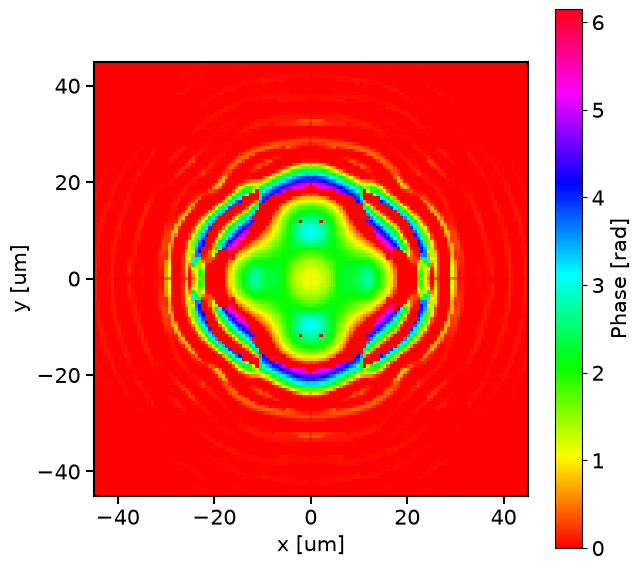

In [102]:
####################################################
#LOAD PHASE MASK 1
#___________________________________________________
#load the phase mask data
phase_mask_1_filename = "full_meta_data/phase_masks_nf/phase_mask_1.npy"
phase_mask_1 = ((np.load(phase_mask_1_filename)).reshape((Nx, Ny)) + 2 * np.pi) % (2 * np.pi)

phase_mask_1_sim = phase_mask_1[sim_mask==1].reshape(Nx_sim, Ny_sim)
fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim, Y_sim, phase_mask_1_sim, cmap='hsv', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Phase [rad]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
#set the same ticks on both axes
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
fig.show()
ax.set_aspect('equal')
phase_mask_1_quadrant = phase_mask_1_sim[nx_sim:, ny_sim:]

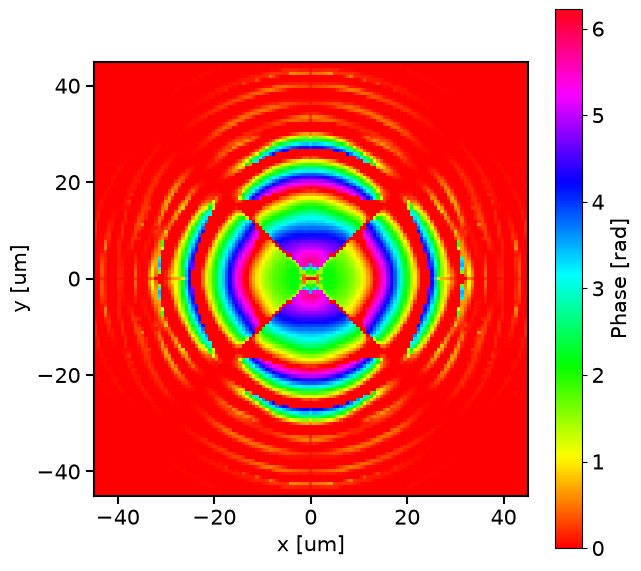

In [103]:
####################################################
#LOAD PHASE MASK 2
#___________________________________________________
#load the phase mask data
phase_mask_2_filename = "full_meta_data/phase_masks_nf/phase_mask_2.npy"
phase_mask_2 = ((np.load(phase_mask_2_filename)).reshape((Nx, Ny)) + 2 * np.pi) % (2 * np.pi)

phase_mask_2_sim = phase_mask_2[sim_mask==1].reshape(Nx_sim, Ny_sim)
fig, ax = plt.subplots()
im = ax.pcolormesh(X_sim, Y_sim, phase_mask_2_sim, cmap='hsv', shading='auto')
ax.set_xlabel('x [um]', fontsize=15)
ax.set_ylabel('y [um]', fontsize=15)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Phase [rad]', fontsize=15)
cbar.ax.tick_params(labelsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
ax.set_xticks((-40,-20,0,20,40))
ax.set_yticks((-40,-20,0,20,40))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
fig.show()
ax.set_aspect('equal')
phase_mask_2_quadrant = phase_mask_2_sim[nx_sim:, ny_sim:]

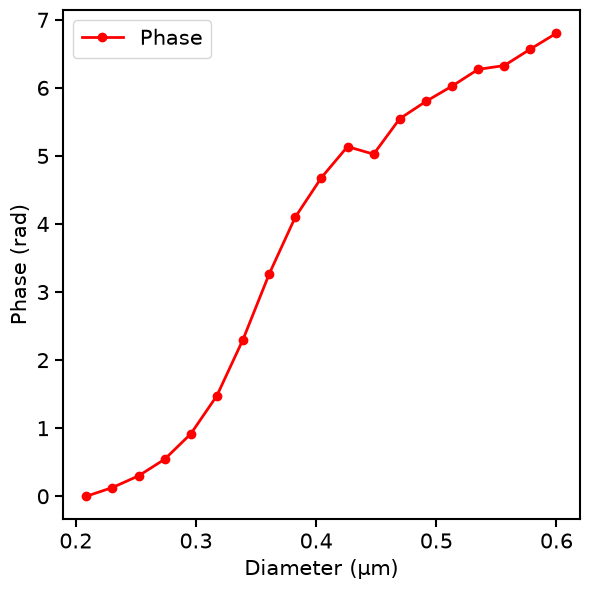

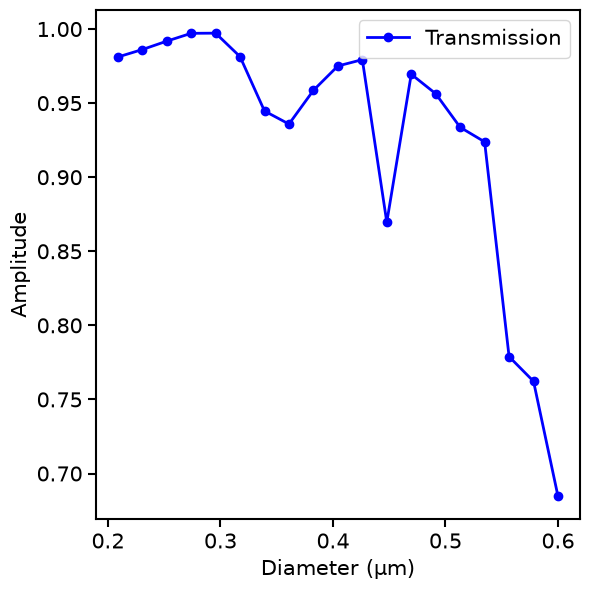

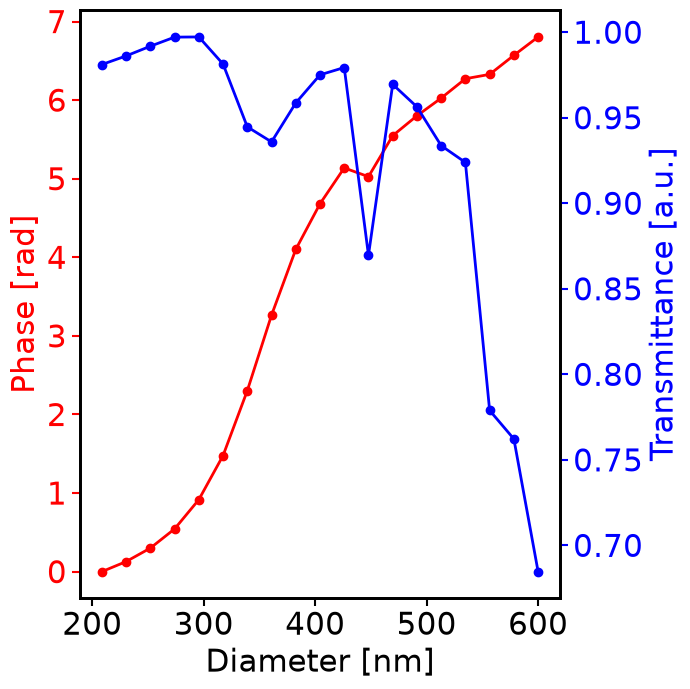

In [21]:
####################################################
#UNIT CELL DATA
#___________________________________________________
#import the unit-cell transmission coefficient data
start_index = 5
unit_cell_diameters = np.load("full_meta_data/unit_cell/unit_cell_center_1550_h900nm_res50_wvl_diameters.npy")[start_index:]
unit_cell_mode_phase = np.load("full_meta_data/unit_cell/unit_cell_center_1550_h900nm_res50_wvl_mode_phase.npy")[start_index:]
unit_cell_mode_phase = np.unwrap(unit_cell_mode_phase - unit_cell_mode_phase[0]) #smallest diameter gets normalized to 0 phase
unit_cell_mode_tran = np.load("full_meta_data/unit_cell/unit_cell_center_1550_h900nm_res50_wvl_mode_tran.npy")[start_index:]

#make a plot of the unit-cell transmission coefficient
fig, ax = plt.subplots(figsize=(6,6))
ax.plot(unit_cell_diameters, unit_cell_mode_phase, 'r-', marker='o', linewidth=2, label='Phase')
ax.set_xlabel('Diameter (µm)', fontsize=15)
ax.set_ylabel('Phase (rad)', fontsize=15)
ax.legend(fontsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(6,6))
ax.plot(unit_cell_diameters, unit_cell_mode_tran, 'b-', marker='o', linewidth=2, label='Transmission')
ax.set_xlabel('Diameter (µm)', fontsize=15)
ax.set_ylabel('Amplitude', fontsize=15)
ax.legend(fontsize=15)
ax.tick_params(labelsize=15, width=1.5, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.show()

#set the plot to a square, same aspect ratio
fig, ax1 = plt.subplots(figsize=(7,7))
ax1.plot(unit_cell_diameters*1e3, unit_cell_mode_phase, 'r-', marker='o', linewidth=2, label='Phase')
ax1.set_xlabel('Diameter [nm]', fontsize=22)
ax1.set_ylabel('Phase [rad]', fontsize=22, color='r')
ax1.tick_params(labelsize=22, width=1.5, length=6, colors='r')
for spine in ax1.spines.values():
    spine.set_linewidth(2.0)

ax2 = ax1.twinx()
ax2.plot(unit_cell_diameters*1e3, unit_cell_mode_tran, 'b-', marker='o', linewidth=2, label='Transmission')
ax2.set_ylabel('Transmittance [a.u.]', fontsize=22, color='b')
ax2.tick_params(labelsize=22, width=1.5, length=6, colors='b')
#aspect ratio

#color of x ticks shall be black
ax1.tick_params(axis='x', colors='k')
ax2.tick_params(axis='x', colors='k')
for spine in ax2.spines.values():
    spine.set_linewidth(2.0)

fig.tight_layout()

plt.savefig("full_meta_results/unit_cell_transmission.pdf")
####################################################

In [105]:
pillars_geo_mask_1 = []
D_vals_mask_1 = []
theta = unit_cell_mode_phase

for i, x in enumerate(xs_sim_quadrant):
    for j, y in enumerate(ys_sim_quadrant):
        if np.sqrt(x**2 + y**2) > max_available_diameter/2:
            continue
        else:
            required_diameter = np.interp(phase_mask_1_quadrant[i,j], theta, unit_cell_diameters)
            #round the required diameter up to three decimal places (nm)
            required_diameter = np.round(required_diameter, 3)
            D_vals_mask_1.append(required_diameter)
            pillar_geo = td.Cylinder(center=(x, y, h/2), radius=required_diameter/2, length=h)
            pillars_geo_mask_1.append(pillar_geo)
print("Number of pillars in simulation domain: ", len(pillars_geo_mask_1))
pillars_mask_1 = td.Structure(geometry=td.GeometryGroup(geometries=pillars_geo_mask_1), medium=si)
print("Max pillar diameter:", np.max(D_vals_mask_1))
print("Min pillar diameter:", np.min(D_vals_mask_1))

Number of pillars in simulation domain:  2645
Max pillar diameter: 0.524
Min pillar diameter: 0.209


In [106]:
pillars_geo_mask_2 = []
D_vals_mask_2 = []
theta = unit_cell_mode_phase

for i, x in enumerate(xs_sim_quadrant):
    for j, y in enumerate(ys_sim_quadrant):
        if np.sqrt(x**2 + y**2) > max_available_diameter/2:
            continue
        else:
            required_diameter = np.interp(phase_mask_2_quadrant[i,j], theta, unit_cell_diameters)
            #round the required diameter up to three decimal places (nm)
            required_diameter = np.round(required_diameter, 3)
            D_vals_mask_2.append(required_diameter)
            pillar_geo = td.Cylinder(center=(x, y, -h/2), radius=required_diameter/2, length=h)
            pillars_geo_mask_2.append(pillar_geo)
print("Number of pillars_mask_2 in simulation domain: ", len(pillars_geo_mask_2))
pillars_mask_2 = td.Structure(geometry=td.GeometryGroup(geometries=pillars_geo_mask_2), medium=si)
print("Max pillar diameter:", np.max(D_vals_mask_2))
print("Min pillar diameter:", np.min(D_vals_mask_2))

Number of pillars_mask_2 in simulation domain:  2645
Max pillar diameter: 0.531
Min pillar diameter: 0.209


In [107]:
#substrate td.Structure definitions
inf_eff = 1e5
substrate_geo_below = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, 0))
substrate_below = td.Structure(geometry=substrate_geo_below, medium=sio2)

substrate_geo_above = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, 0), rmax=(inf_eff, inf_eff, inf_eff))
substrate_above = td.Structure(geometry=substrate_geo_above, medium=sio2)

all_substrate_geo = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, inf_eff))
all_substrate = td.Structure(geometry=all_substrate_geo, medium=sio2) 

all_air_geo = td.Box.from_bounds(rmin=(-inf_eff, -inf_eff, -inf_eff), rmax=(inf_eff, inf_eff, inf_eff))
all_air = td.Structure(geometry=all_air_geo, medium=air)

In [108]:
#simulation domain size
Lx = max_sim_size
Ly = max_sim_size
Lz = sim_z_size

source_x_size = max_sim_size
source_y_size = max_sim_size

#far field points the projection monitor will compute the field at
Nx_far = 401
Ny_far = 401
xs_far = np.linspace(-Lx/2, Lx/2, Nx_far)
ys_far = np.linspace(-Ly/2, Ly/2, Ny_far)
X_far, Y_far = np.meshgrid(xs_far, ys_far)

In [109]:
#simulation
run_time = 5e-12
source_time = td.GaussianPulse(freq0=freq0, fwidth=fwidth, phase=0)

grid_per_unit_length = 15
grid_x = td.UniformGrid(dl = unit_cell_pitch / grid_per_unit_length)
#grid_x = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_y = td.UniformGrid(dl = unit_cell_pitch / grid_per_unit_length)
#grid_y = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_z = td.AutoGrid(min_steps_per_wvl=grid_per_unit_length)
grid_spec = td.GridSpec(wavelength=lda0, grid_x = grid_x, grid_y = grid_y, grid_z = grid_z)

#we overlay a box structure over the position of the pillars. This is done for the following reason.
#The meshing over the pillars requires many steps, since the refractive index changes
#from pillar to air. Instead of having to parse all these transitions, especially since we
#have a large number of pillars, we can simply overlay a box of the same material as the pillars.
#In this way, preprocessing becomes faster because all the region is treated uniformly. 
# The material is the same as the pillars, i.e., silicon
#to ensure the mesh is finer, compared to the surrounding air.

grid_spec_0 = grid_spec.copy()

grid_spec_1 = grid_spec.copy(
    update = dict(
        override_structures=[
            td.Structure(
                geometry=td.Box.from_bounds(
                    rmin = (-td.inf, -td.inf, 0),
                    rmax = (td.inf, td.inf, h)
                ),
                medium = si,
            )
        ]
    )
)

grid_spec_2 = grid_spec.copy(
    update = dict(
        override_structures=[
            td.Structure(
                geometry=td.Box.from_bounds(
                    rmin = (-td.inf, -td.inf, -h),
                    rmax = (td.inf, td.inf, 0)
                ),
                medium = si,
            )
        ]
    )
)

In [110]:
mnt_yz = td.FieldMonitor(
    center=(0, 0, 0), 
    size=(0, td.inf, td.inf), 
    freqs=[freq0], 
    name="field_yz",
)

#flux monitors to compute reflectance and transmittance
transmittance_flux_monitor_0 = td.FluxMonitor(
    center=[0, 0, lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="transmittance_flux_monitor_0",
)

reflectance_flux_monitor_0 = td.FluxMonitor(
    center=[0, 0, - (lda0/2)],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="reflectance_flux_monitor_0",
)

transmittance_flux_monitor_norm = td.FluxMonitor(
    center=[0, 0, h + lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="transmittance_flux_monitor_norm",
)

reflectance_flux_monitor_norm = td.FluxMonitor(
    center=[0, 0, - (lda0/2 + 0.1)],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="reflectance_flux_monitor_norm",
)

transmittance_flux_monitor_1 = td.FluxMonitor(
    center=[0, 0, h + lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="transmittance_flux_monitor_1",
)

reflectance_flux_monitor_1 = td.FluxMonitor(
    center=[0, 0, - (lda0/2 + 0.1)],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="reflectance_flux_monitor_1",
)

transmittance_flux_monitor_2 = td.FluxMonitor(
    center=[0, 0, lda0/2],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="transmittance_flux_monitor_2",
)

reflectance_flux_monitor_2 = td.FluxMonitor(
    center=[0, 0, - (h + lda0/2 + 0.1)],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="reflectance_flux_monitor_2",
)

In [111]:
source_position_0 = 0
source_position_1 = - (lda0 / 2)
source_position_2 = - (h + lda0 / 2)

In [112]:
input_E_field_fiber_facet = np.load("full_meta_data/input_field/SMF_LP01_field_distribution_lda_1550_N_1025.npy")
input_H_field_fiber_facet = np.load("full_meta_data/input_field/SMF_LP01_magnetic_field_distribution_lda_1550_N_1025.npy")

input_E_field_fiber_facet = input_E_field_fiber_facet[sim_mask == 1].reshape(Nx_sim, Ny_sim)
input_H_field_fiber_facet = input_H_field_fiber_facet[sim_mask == 1].reshape(Nx_sim, Ny_sim)

#plot the imported fields
fig, ax = plt.subplots(1,2,figsize=(14, 7))
ax[0].pcolormesh(X_sim, Y_sim, np.abs(input_E_field_fiber_facet), shading='auto', rasterized = True)
ax[1].pcolormesh(X_sim, Y_sim, (np.angle(input_E_field_fiber_facet)+2*np.pi)%(2*np.pi), shading='auto', cmap='hsv', rasterized = True)
#ax[1,0].pcolormesh(X_sim, Y_sim, np.abs(input_H_field_fiber_facet), shading='auto')
#ax[1,1].pcolormesh(X_sim, Y_sim, (np.angle(input_H_field_fiber_facet)+2*np.pi)%(2*np.pi), shading='auto', cmap='hsv')
ax[0].set_xlabel('x [µm]', fontsize=15)
ax[0].set_ylabel('Amplitude [a.u.]', fontsize=15)
ax[1].set_xlabel('x [µm]', fontsize=15)
ax[1].set_ylabel('Phase [rad]', fontsize=15)
for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/input_field.pdf")
plt.close()

#cross section of the fields
fig, ax = plt.subplots(figsize=(7, 7))
test_mode_field_diameter = 8.3 #the mode field diameter is twice the beam waist
test_beam_waist = test_mode_field_diameter / 2 #the beam waist is the radius at which the field amplitude drops to 1/e of its maximum value
radius = np.sqrt(X_sim ** 2 + Y_sim ** 2)
test_gaussian = np.exp(-(radius[Nx_sim//2,:]**2)/(2*test_beam_waist**2))

ax.axhline(np.exp(-1), color='r', linestyle='--')
ax.text(-40, np.exp(-1) + 0.05, f'$w_0 = {test_beam_waist} [µm]$', color='r', fontsize=15)
ax.plot(X_sim[Nx_sim//2,:], np.abs(input_E_field_fiber_facet[Nx_sim//2,:]) / np.max(np.abs(input_E_field_fiber_facet[Nx_sim//2,:])), label='SMF LP01')
ax.plot(X_sim[Nx_sim//2,:], test_gaussian, '--', label='fitted Gaussian')
ax.set_xlabel('x [µm]', fontsize=15)
ax.set_ylabel('Amplitude [a.u.]', fontsize=15)
ax.set_xlim(X_sim[Nx_sim//2,0], X_sim[Nx_sim//2,-1])
ax.legend(fontsize=15, loc='upper left')
ax.tick_params(labelsize=15, width=1.5, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

plt.tight_layout()
plt.savefig("full_meta_results/plots/input_field_cross_section.pdf")
plt.close()

In [113]:
dataset_input_EH_0 = td.FieldDataset(
    Ex = td.ScalarFieldDataArray(
        input_E_field_fiber_facet[..., None, None],
        coords={
            "x": xs_sim,
            "y": ys_sim,
            "z": [source_position_0],
            "f": [freq0],
        },
    ),
    Hy = td.ScalarFieldDataArray(
        input_H_field_fiber_facet[..., None, None],
        coords={
            "x": xs_sim,
            "y": ys_sim,
            "z": [source_position_0],
            "f": [freq0],
        },
    ),
)

custom_src_0 = td.CustomFieldSource(
    source_time = source_time,
    center = (0, 0, source_position_0),
    size = (source_x_size, source_y_size, 0),
    field_dataset = dataset_input_EH_0
)

#distance from the monitor custom origin to the far-field plane
projection_distance_0 = d0 - source_position_1

monitor_proj_0 = td.FieldProjectionCartesianMonitor(
    center=[0, 0, 0.5*lda0],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="ff_proj_monitor_0",
    proj_axis=2,
    proj_distance=projection_distance_0,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, 0),
    far_field_approx=False,
)

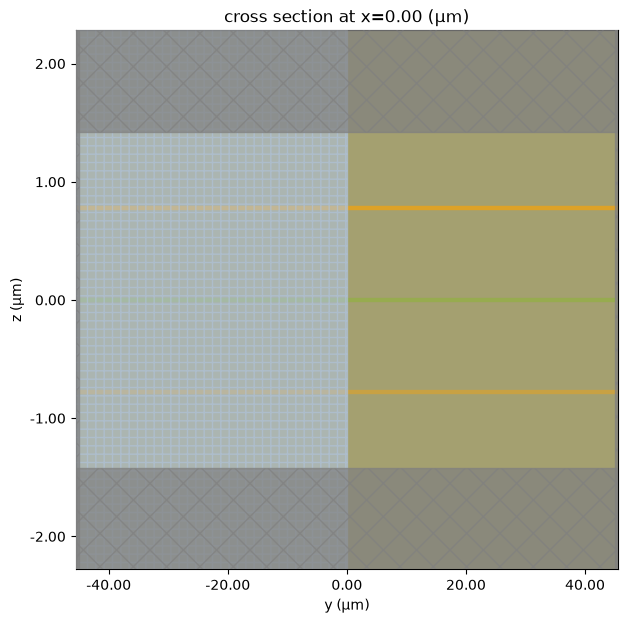

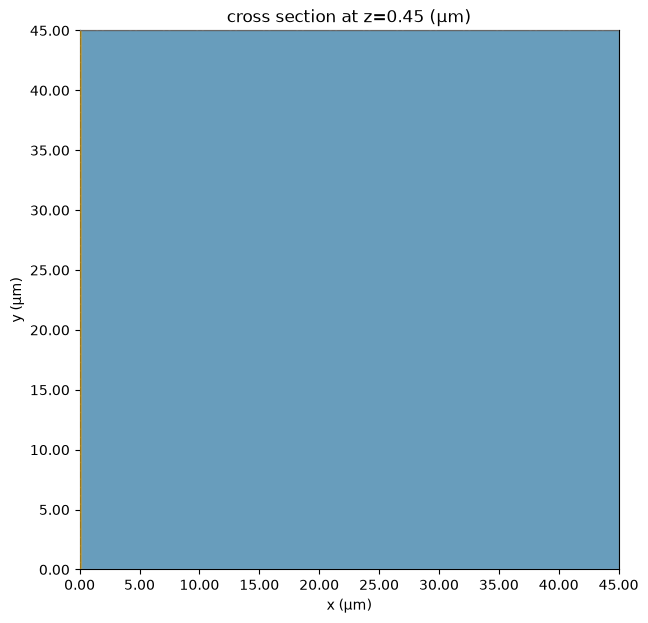

In [114]:
sim0 = td.Simulation(
    center=[0, 0, 0],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_0,
    structures=[all_substrate],
    sources=[custom_src_0],
    monitors=[transmittance_flux_monitor_0, reflectance_flux_monitor_0, monitor_proj_0, mnt_yz],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim0.plot(x=0, ax=ax,)
ax.set_aspect('auto')
plt.show()

fig, ax = plt.subplots()
sim0.plot(z=h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()

In [115]:
# job = web.Job(simulation=sim0, task_name="full_meta0")
# estimated_cost = web.estimate_cost(job.task_id)

In [116]:
#sim_data_0 = job.run(path="full_meta_results/full_meta0.hdf5")

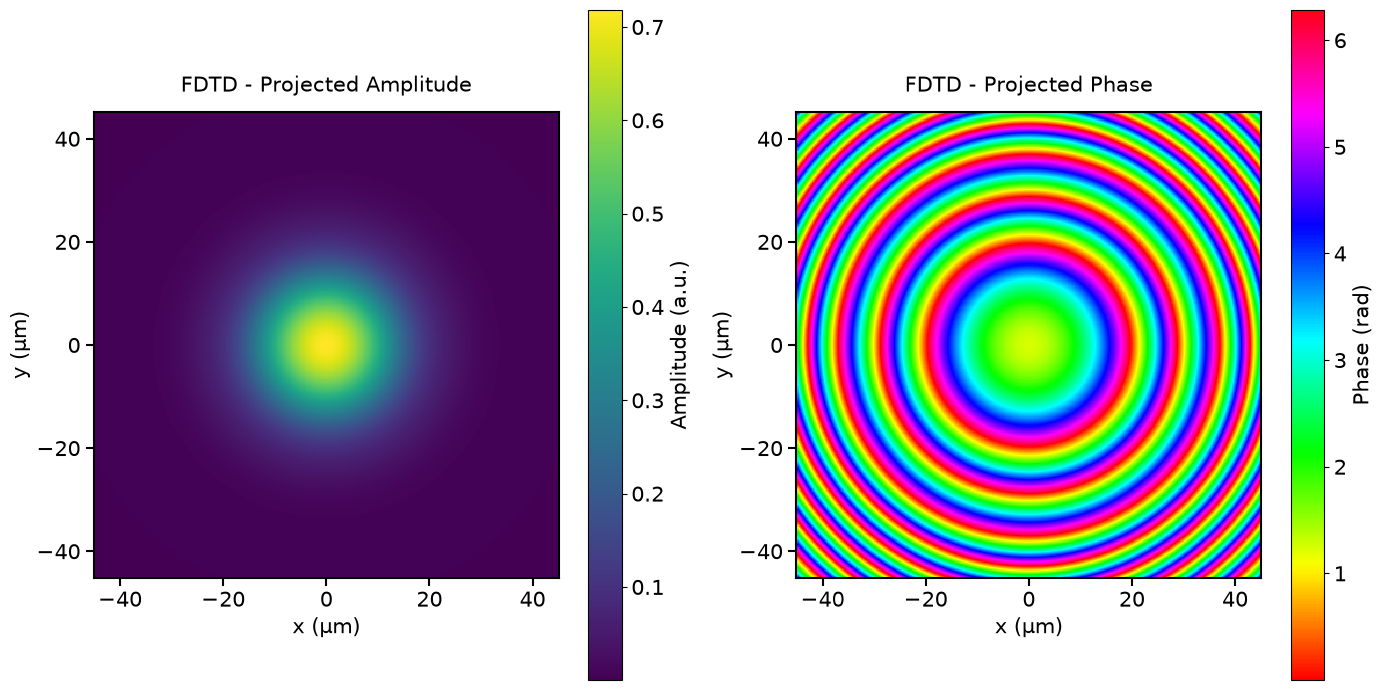

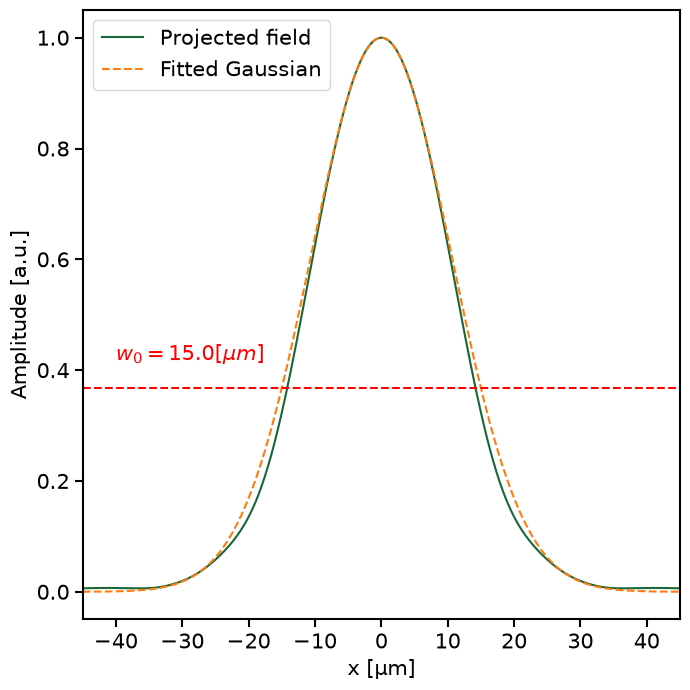

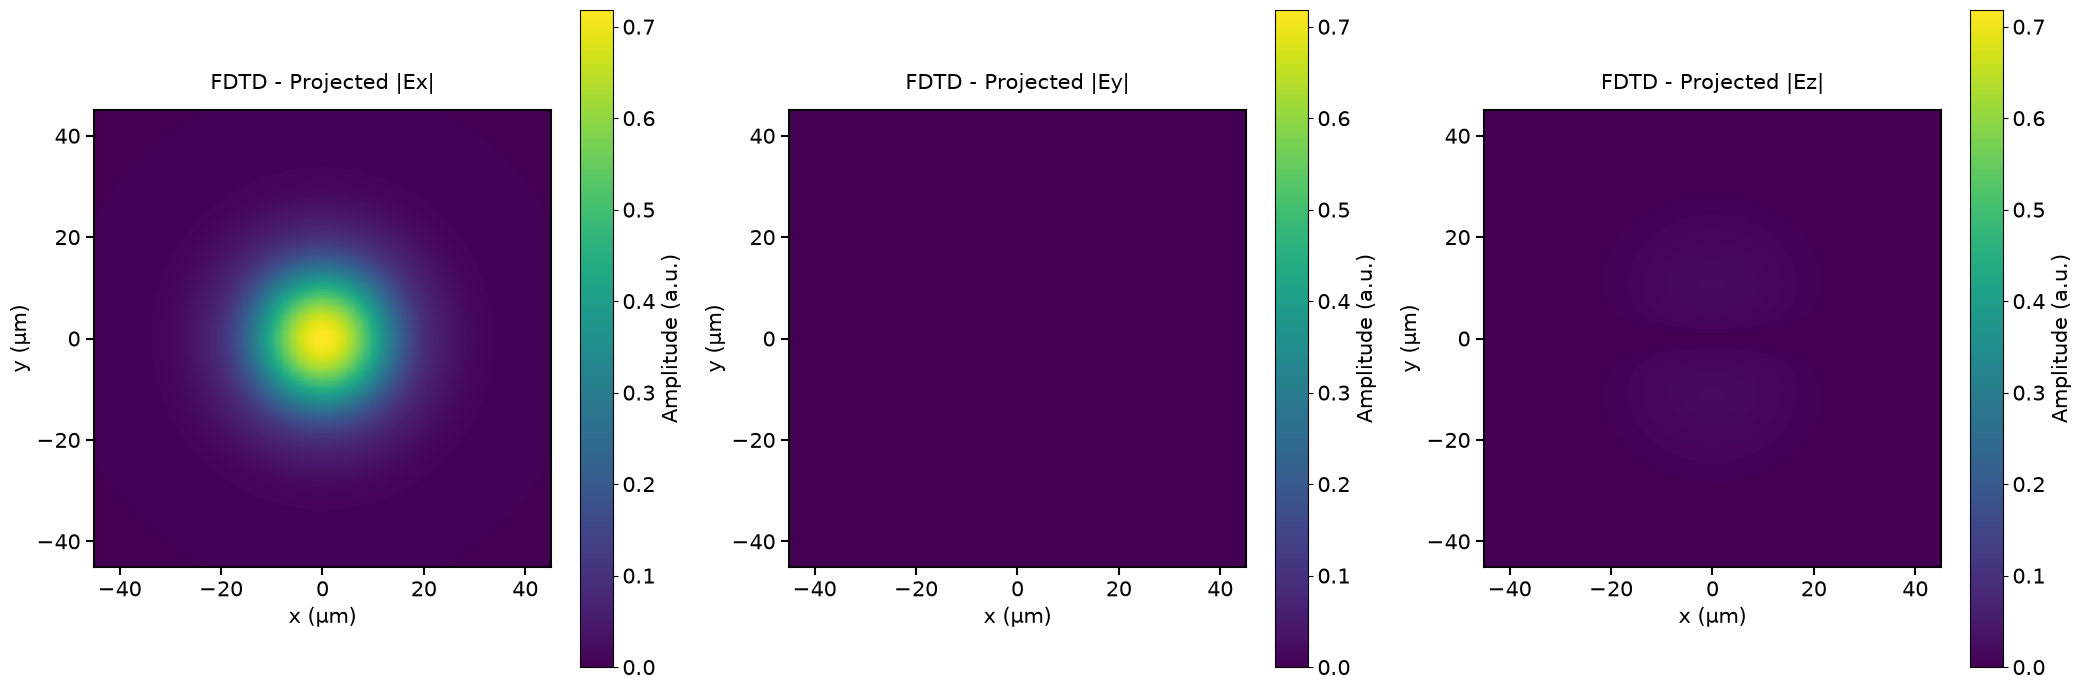

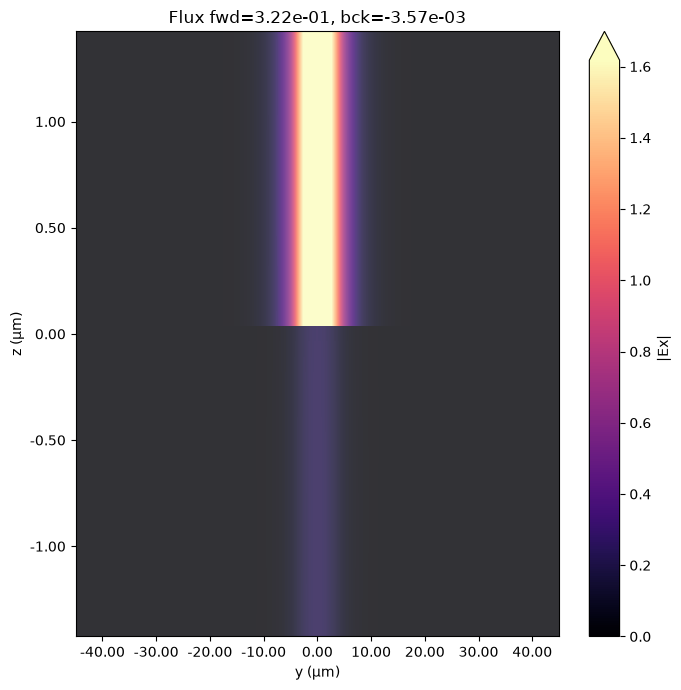

FDTD forward flux: 0.32239726185798645


In [117]:
sim_data_0 = SimulationData.from_file(fname="full_meta_results/full_meta0.hdf5")

proj_Ex_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Ex.sel(f=freq0, z=projection_distance_0)
proj_Ey_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Ey.sel(f=freq0, z=projection_distance_0)
proj_Ez_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Ez.sel(f=freq0, z=projection_distance_0)
proj_Hx_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Hx.sel(f=freq0, z=projection_distance_0)
proj_Hy_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Hy.sel(f=freq0, z=projection_distance_0)
proj_Hz_field_0 = sim_data_0["ff_proj_monitor_0"].fields_cartesian.Hz.sel(f=freq0, z=projection_distance_0)

np.save("full_meta_results/proj_Ex_field_0.npy", proj_Ex_field_0)
np.save("full_meta_results/proj_Ey_field_0.npy", proj_Ey_field_0)
np.save("full_meta_results/proj_Ez_field_0.npy", proj_Ez_field_0)
np.save("full_meta_results/proj_Hx_field_0.npy", proj_Hx_field_0)
np.save("full_meta_results/proj_Hy_field_0.npy", proj_Hy_field_0)
np.save("full_meta_results/proj_Hz_field_0.npy", proj_Hz_field_0)

fig, ax = plt.subplots(1,2,figsize=(14, 7))

im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_0), shading='auto', cmap='viridis',rasterized=True)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_title("FDTD - Projected Amplitude", fontsize=15, pad=15)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="Amplitude (a.u.)")
cbar0.set_label("Amplitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, (np.angle(proj_Ex_field_0)+2*np.pi)%(2*np.pi), shading='auto', cmap='hsv',rasterized=True)
ax[1].set_title("FDTD - Projected Phase", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="Phase (rad)")
cbar1.set_label("Phase (rad)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta0_proj_Ex_field.pdf", bbox_inches='tight', dpi=300)

#slice of the projected Ex component
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(X_far[X_far.shape[0]//2,:], np.abs(proj_Ex_field_0[X_far.shape[0]//2,:]) / np.max(np.abs(proj_Ex_field_0[X_far.shape[0]//2,:])), label='Projected field')
fitted_mode_diameter = 30
fitted_beam_waist = fitted_mode_diameter / 2
rho_squared_proj = X_far ** 2 + Y_far ** 2
fitted_gaussian = np.exp(- rho_squared_proj / fitted_beam_waist**2)
ax.plot(X_far[X_far.shape[0]//2,:], fitted_gaussian[X_far.shape[0]//2,:] / np.max(fitted_gaussian[X_far.shape[0]//2,:]), linestyle='--', label='Fitted Gaussian')
ax.axhline(np.exp(-1), color='r', linestyle='--')
ax.text(-40, np.exp(-1) + 0.05, f'$w_0 = {fitted_beam_waist} [µm]$', color='r', fontsize=15)
ax.set_xlabel('x [µm]',fontsize=15)
ax.set_ylabel('Amplitude [a.u.]',fontsize=15)
ax.set_xlim(X_far[X_far.shape[0]//2,0], X_far[X_far.shape[0]//2,-1])
ax.legend(fontsize=15, loc='upper left')
ax.tick_params(labelsize=15, width=1.5, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta0_proj_Ex_field_cross_section.pdf", bbox_inches='tight', dpi=300)

fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="Amplitude (a.u.)")
cbar0.set_label("Amplitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="Amplitude (a.u.)")
cbar1.set_label("Amplitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_0), shading='auto', cmap='viridis',rasterized=True, vmin = 0, vmax = np.max(np.abs(proj_Ex_field_0)))
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="Amplitude (a.u.)")
cbar2.set_label("Amplitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta0_proj_E_field_intensity.pdf", bbox_inches='tight', dpi=300)

#plot the flux to observe source directionality
fig, ax = plt.subplots(1)
sim_data_0.plot_field("field_yz", field_name="Ex", val="abs", ax=ax)
ax.set_xlim([-sim0.size[0] / 2, sim0.size[0] / 2])
ax.set_ylim([-sim0.size[2] / 2, sim0.size[2] / 2])
ax.set_title(
    f"Flux fwd={float(sim_data_0['transmittance_flux_monitor_0'].flux.item()):1.2e}, bck={float(sim_data_0['reflectance_flux_monitor_0'].flux.item()):1.2e}"
)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
forward_flux_0 = float(sim_data_0['transmittance_flux_monitor_0'].flux.item())
print("FDTD forward flux:", forward_flux_0)

In [118]:
#import the input field (just before MS1)
input_Ex_field_before_MS1 = np.load("full_meta_results/proj_Ex_field_0.npy")
input_Ey_field_before_MS1 = np.load("full_meta_results/proj_Ey_field_0.npy")
input_Ez_field_before_MS1 = np.load("full_meta_results/proj_Ez_field_0.npy")
input_Hx_field_before_MS1 = np.load("full_meta_results/proj_Hx_field_0.npy")  
input_Hy_field_before_MS1 = np.load("full_meta_results/proj_Hy_field_0.npy")
input_Hz_field_before_MS1 = np.load("full_meta_results/proj_Hz_field_0.npy")

print("Input Ex field shape:", input_Ex_field_before_MS1.shape)

#custom source field definition
dataset_input_EH_1 = td.FieldDataset(
    Ex = td.ScalarFieldDataArray(
        input_Ex_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
    Ey = td.ScalarFieldDataArray(
        input_Ey_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
    Ez = td.ScalarFieldDataArray(
        input_Ez_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
    Hx = td.ScalarFieldDataArray(
        input_Hx_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
    Hy = td.ScalarFieldDataArray(
        input_Hy_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
    Hz = td.ScalarFieldDataArray(
        input_Hz_field_before_MS1[..., None, None],
        coords={
            "x": xs_far,
            "y": xs_far,
            "z": [source_position_1],
            "f": [freq0],
        },
    ),
)

custom_src_1 = td.CustomFieldSource(
    source_time = source_time,
    center = (0, 0, source_position_1),
    size = (source_x_size, source_y_size, 0),
    field_dataset = dataset_input_EH_1
)

Input Ex field shape: (401, 401)


In [119]:
#distance from the monitor custom origin to the far-field plane
projection_distance_1 = d1 - lda0 / 2

monitor_proj_1 = td.FieldProjectionCartesianMonitor(
    center=[0, 0, h + 0.5*lda0],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="ff_proj_monitor_1",
    proj_axis=2,
    proj_distance=projection_distance_1,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, h),
    far_field_approx=False,
)

17:36:13 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

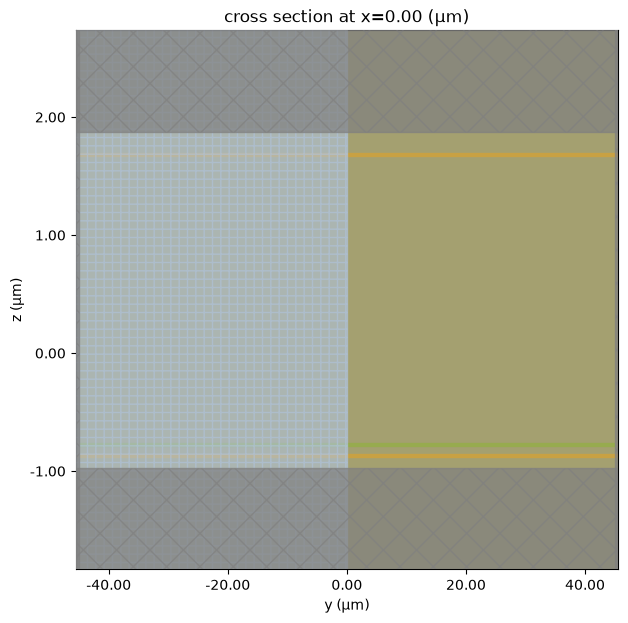

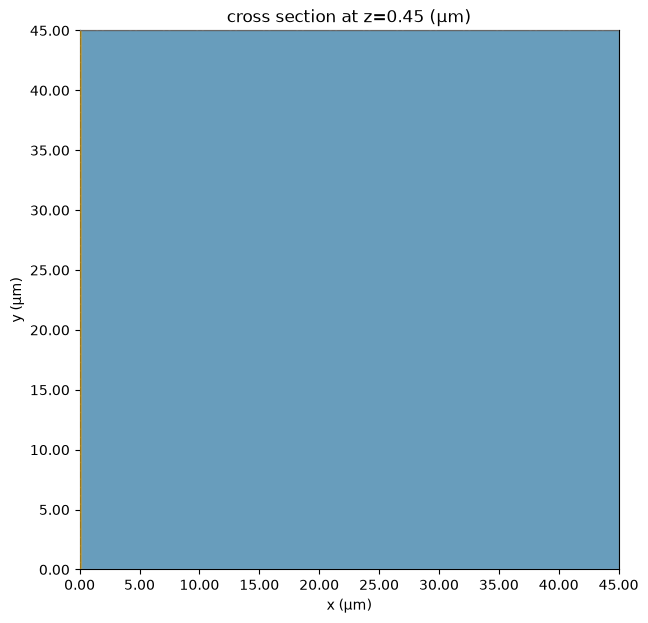

In [120]:
#use this to check on the normalized fields
sim_normalization = td.Simulation(
    center=[0, 0, h/2],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_1,
    structures=[all_substrate],
    sources=[custom_src_1],
    monitors=[reflectance_flux_monitor_norm, transmittance_flux_monitor_norm, mnt_yz],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim_normalization.plot(x=0, ax=ax,)
ax.set_aspect('auto')
plt.show()

fig, ax = plt.subplots()
sim_normalization.plot(z=h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()

In [121]:
# job_norm = web.Job(simulation=sim_normalization, task_name="full_meta1_normalization")
# estimated_cost = web.estimate_cost(job_norm.task_id)

In [122]:
#sim_norm_data = job_norm.run(path="full_meta_results/sim_norm.hdf5")

17:36:14 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

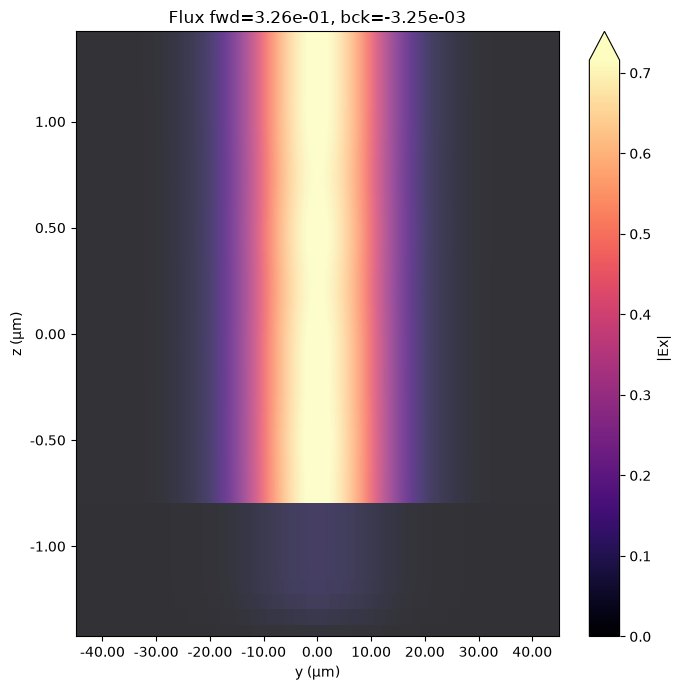

Forward flux (normalization): 3.26e-01
Backward flux (normalization): -3.25e-03


In [123]:
#plot the flux to observe source directionality
sim_norm_data = SimulationData.from_file(fname="full_meta_results/sim_norm.hdf5")
fig, ax = plt.subplots(1)
sim_norm_data.plot_field("field_yz", field_name="Ex", val="abs", ax=ax)
ax.set_xlim([-sim_normalization.size[0] / 2, sim_normalization.size[0] / 2])
ax.set_ylim([-sim_normalization.size[2] / 2, sim_normalization.size[2] / 2])
ax.set_title(
    f"Flux fwd={float(sim_norm_data['transmittance_flux_monitor_norm'].flux.item()):1.2e}, bck={float(sim_norm_data['reflectance_flux_monitor_norm'].flux.item()):1.2e}"
)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
forward_flux_norm_1 = float(sim_norm_data['transmittance_flux_monitor_norm'].flux.item())  
backward_flux_norm_1 = float(sim_norm_data['reflectance_flux_monitor_norm'].flux.item())
print(f"Forward flux (normalization): {forward_flux_norm_1:1.2e}")
print(f"Backward flux (normalization): {backward_flux_norm_1:1.2e}")

17:36:16 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

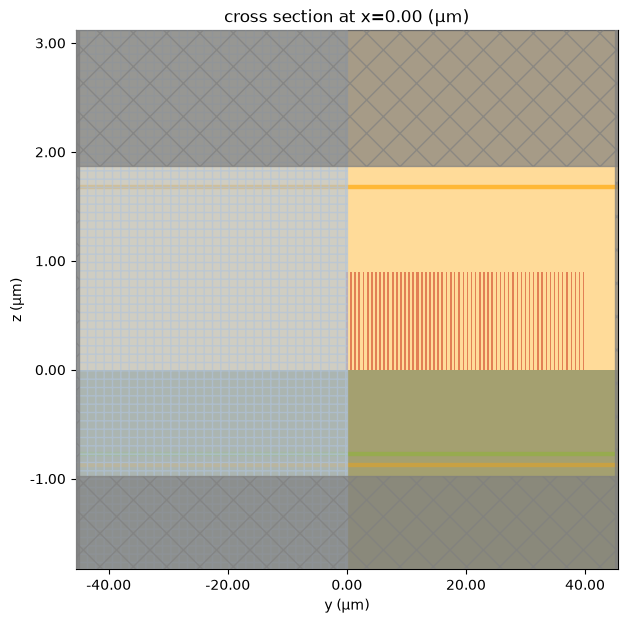

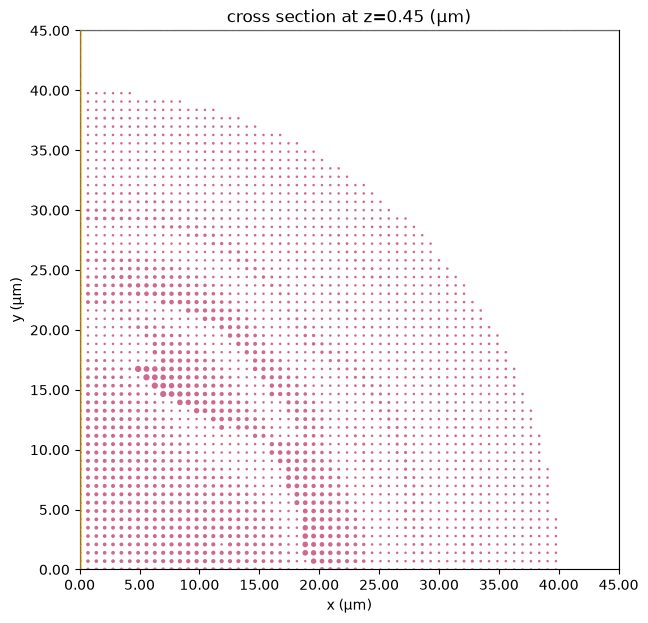

In [124]:
sim1 = td.Simulation(
    center=[0, 0, h/2],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_1,
    structures=[substrate_below, pillars_mask_1],
    sources=[custom_src_1],
    monitors=[reflectance_flux_monitor_1, transmittance_flux_monitor_1, monitor_proj_1, mnt_yz],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim1.plot(x=0, ax=ax,)
ax.set_aspect('auto')
plt.show()

fig, ax = plt.subplots()
sim1.plot(z=h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()

In [125]:
# job = web.Job(simulation=sim1, task_name="full_meta1")
# estimated_cost = web.estimate_cost(job.task_id)

In [126]:
#sim_data_1 = job.run(path="full_meta_results/full_meta1.hdf5")

17:36:21 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

tot_flux_1: 0.34247318655252457
front/back ratio: 10.333669074717292
transmittance (comp): 0.9584776719833055


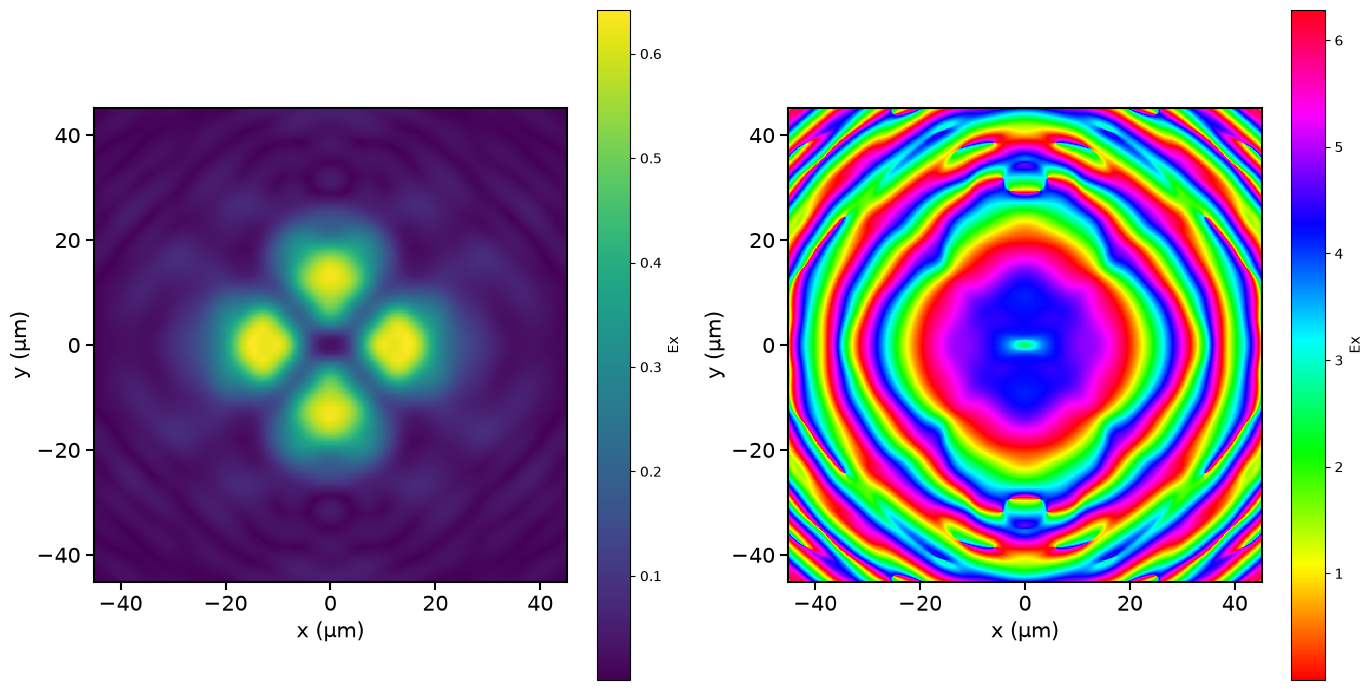

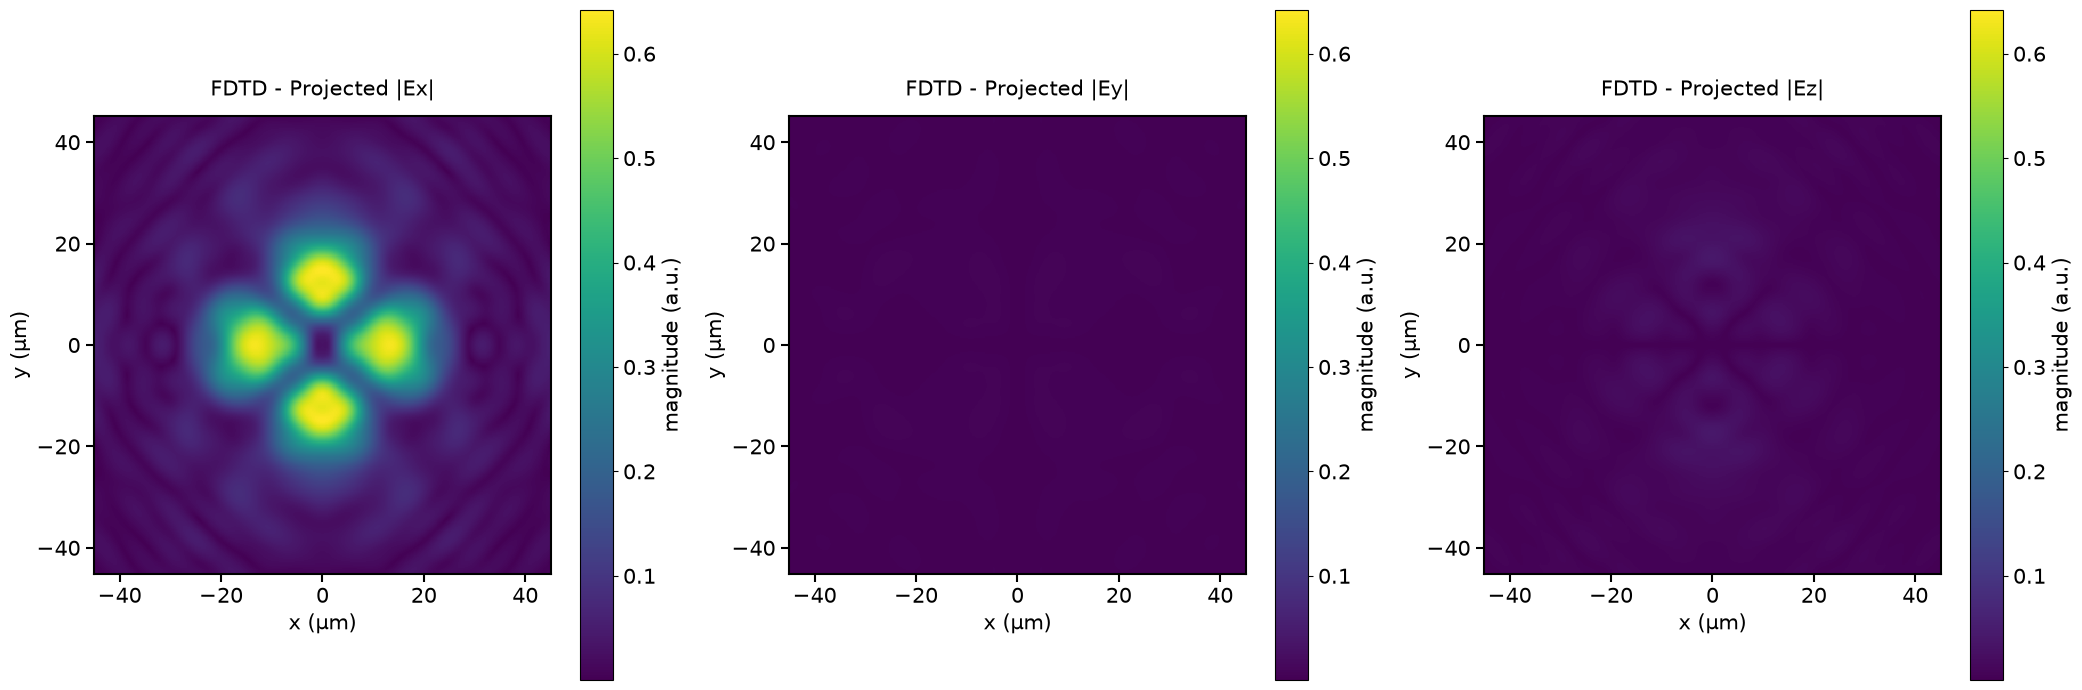

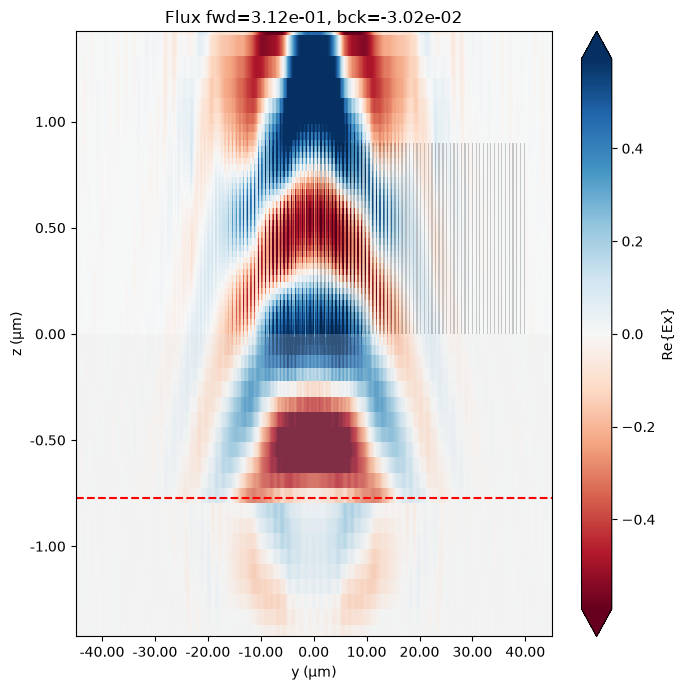

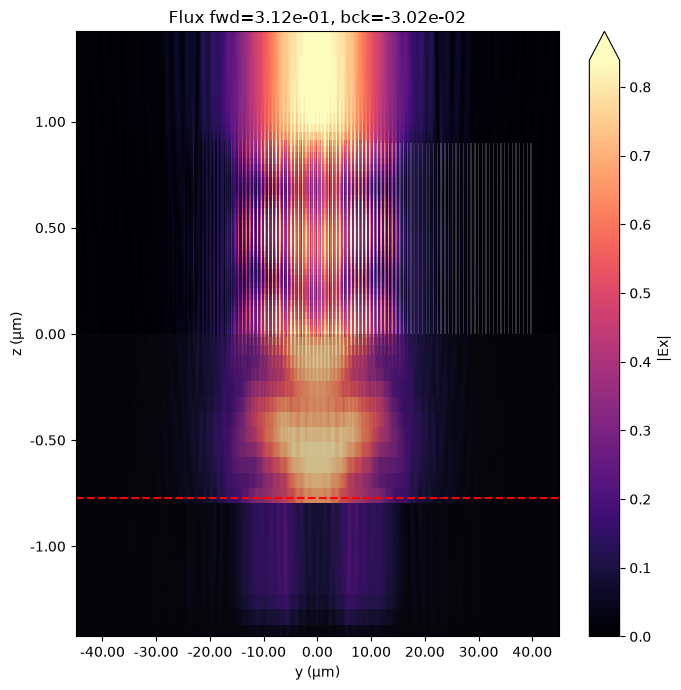

Forward flux (raw): 3.12e-01
Backward flux (raw): -3.02e-02


In [127]:
sim_data_1 = SimulationData.from_file(fname="full_meta_results/full_meta1.hdf5")

forward_flux_1 = float(sim_data_1['transmittance_flux_monitor_1'].flux.item())
forward_flux_1_comp = forward_flux_1 / forward_flux_norm_1

backward_flux_1 = float(sim_data_1['reflectance_flux_monitor_1'].flux.item())
tot_flux_1 = forward_flux_1 - backward_flux_1

forward_ratio_1 = forward_flux_1 / tot_flux_1
backward_ratio_1 = - backward_flux_1 / tot_flux_1
fb_ratio = forward_ratio_1 / backward_ratio_1

print("tot_flux_1:", tot_flux_1)
print("front/back ratio:", fb_ratio)
print("transmittance (comp):", forward_flux_1_comp)

proj_Ex_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Ex.sel(f=freq0, z=projection_distance_1)
proj_Ey_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Ey.sel(f=freq0, z=projection_distance_1)
proj_Ez_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Ez.sel(f=freq0, z=projection_distance_1)
proj_Hx_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Hx.sel(f=freq0, z=projection_distance_1)
proj_Hy_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Hy.sel(f=freq0, z=projection_distance_1)
proj_Hz_field_1 = sim_data_1["ff_proj_monitor_1"].fields_cartesian.Hz.sel(f=freq0, z=projection_distance_1)

np.save("full_meta_results/proj_Ex_field_1.npy", proj_Ex_field_1)
np.save("full_meta_results/proj_Ey_field_1.npy", proj_Ey_field_1)
np.save("full_meta_results/proj_Ez_field_1.npy", proj_Ez_field_1)
np.save("full_meta_results/proj_Hx_field_1.npy", proj_Hx_field_1)
np.save("full_meta_results/proj_Hy_field_1.npy", proj_Hy_field_1)
np.save("full_meta_results/proj_Hz_field_1.npy", proj_Hz_field_1)

fig, ax = plt.subplots(1,2,figsize=(14, 7))
np.abs(proj_Ex_field_1).plot(ax=ax[0], x = 'x', y = 'y', rasterized=True)
phase_Ex_field_1 = proj_Ex_field_1.copy(
    data = np.mod(np.angle(proj_Ex_field_1), 2*np.pi)
)
phase_Ex_field_1.plot(ax=ax[1], x = 'x', y = 'y', rasterized=True, cmap='hsv')
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
ax[0].set_title("")
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
ax[1].set_title("")
for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta1_proj_Ex_field_1.pdf", bbox_inches='tight', dpi=300)

fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="magnitude (a.u.)")
cbar0.set_label("magnitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="magnitude (a.u.)")
cbar1.set_label("magnitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_1), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_1).max(), vmin = np.abs(proj_Ex_field_1).min())
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="magnitude (a.u.)")
cbar2.set_label("magnitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta1_proj_E_field_intensity.pdf", bbox_inches='tight', dpi=300)

#plot: real part of the Ex field on the yz plane
fig, ax = plt.subplots(1)
sim_data_1.plot_field("field_yz", field_name="Ex", val="real", ax=ax)
ax.set_xlim([-sim1.size[0] / 2, sim1.size[0] / 2])
ax.set_ylim([-sim1.size[2] / 2, sim1.size[2] / 2])
ax.set_title(
    f"Flux fwd={float(sim_data_1['transmittance_flux_monitor_1'].flux.item()):1.2e}, bck={float(sim_data_1['reflectance_flux_monitor_1'].flux.item()):1.2e}"
)
ax.axhline(source_position_1, color='red', linestyle='--', linewidth=1.5)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()

#plot: flux to observe source directionality
fig, ax = plt.subplots(1)
sim_data_1.plot_field("field_yz", field_name="Ex", val="abs", ax=ax)
ax.set_xlim([-sim1.size[0] / 2, sim1.size[0] / 2])
ax.set_ylim([-sim1.size[2] / 2, sim1.size[2] / 2])
ax.set_title(
    f"Flux fwd={float(sim_data_1['transmittance_flux_monitor_1'].flux.item()):1.2e}, bck={float(sim_data_1['reflectance_flux_monitor_1'].flux.item()):1.2e}"
)
ax.axhline(source_position_1, color='red', linestyle='--', linewidth=1.5)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
forward_flux_raw_1 = float(sim_data_1['transmittance_flux_monitor_1'].flux.item())  
backward_flux_raw_1 = float(sim_data_1['reflectance_flux_monitor_1'].flux.item())
print(f"Forward flux (raw): {forward_flux_raw_1:1.2e}")
print(f"Backward flux (raw): {backward_flux_raw_1:1.2e}")

In [128]:
input_Ex_field_before_MS2 = np.load("full_meta_results/proj_Ex_field_1.npy")
input_Ey_field_before_MS2 = np.load("full_meta_results/proj_Ey_field_1.npy")
input_Ez_field_before_MS2 = np.load("full_meta_results/proj_Ez_field_1.npy")
input_Hx_field_before_MS2 = np.load("full_meta_results/proj_Hx_field_1.npy")
input_Hy_field_before_MS2 = np.load("full_meta_results/proj_Hy_field_1.npy")
input_Hz_field_before_MS2 = np.load("full_meta_results/proj_Hz_field_1.npy")

dataset_input_EH_2 = td.FieldDataset(
    Ex = td.ScalarFieldDataArray(
        input_Ex_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
    Ey = td.ScalarFieldDataArray(
        input_Ey_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
    Ez = td.ScalarFieldDataArray(
        input_Ez_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
    Hx = td.ScalarFieldDataArray(
        input_Hx_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
    Hy = td.ScalarFieldDataArray(
        input_Hy_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
    Hz = td.ScalarFieldDataArray(
        input_Hz_field_before_MS2[..., None, None],
        coords={
            "x": xs_far,
            "y": ys_far,
            "z": [source_position_2],
            "f": [freq0],
        },
    ),
)

custom_src_2 = td.CustomFieldSource(
    source_time = source_time,
    center = (0, 0, source_position_2),
    size = (source_x_size, source_y_size, 0),
    field_dataset = dataset_input_EH_2
)

In [129]:
projection_distance_output_field = d2

monitor_proj_output_field = td.FieldProjectionCartesianMonitor(
    center=[0, 0, 0.5*lda0],
    size=[td.inf, td.inf, 0],
    freqs=[freq0],
    name="ff_proj_monitor_output_field",
    proj_axis=2,
    proj_distance=projection_distance_output_field,
    x=xs_far,
    y=ys_far,
    custom_origin=(0, 0, 0),
    far_field_approx=False,
)

17:36:31 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

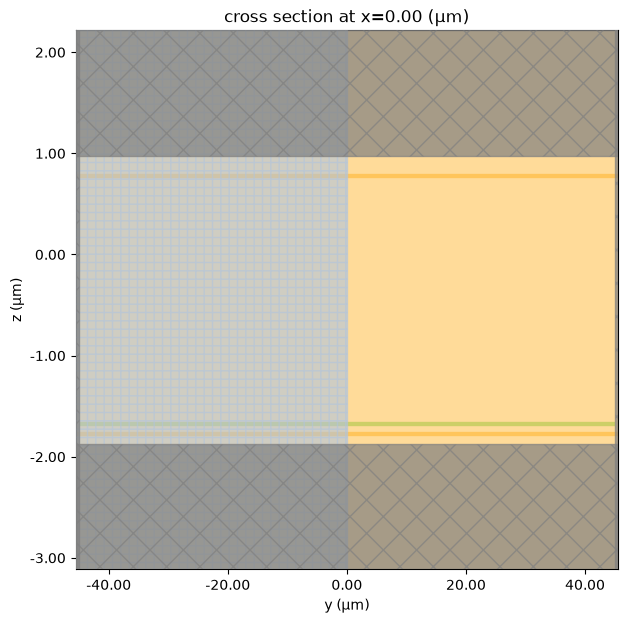

In [130]:
#use this to check on the normalized fields
sim_normalization_2 = td.Simulation(
    center=[0, 0, -h/2],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_2,
    structures=[all_air],
    sources=[custom_src_2],
    monitors=[reflectance_flux_monitor_2, transmittance_flux_monitor_2, mnt_yz],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x = td.Boundary.pml(), y = td.Boundary.pml(), z = td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim_normalization_2.plot(x = 0, ax = ax,)
ax.set_aspect('auto')
plt.show()

In [131]:
# job = web.Job(simulation = sim_normalization_2, task_name = "full_meta2_normalization")
# estimated_cost = web.estimate_cost(job.task_id)

In [132]:
#sim_norm_2_data = job.run(path="full_meta_results/full_meta2_normalization.hdf5")

17:36:32 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

-1.675


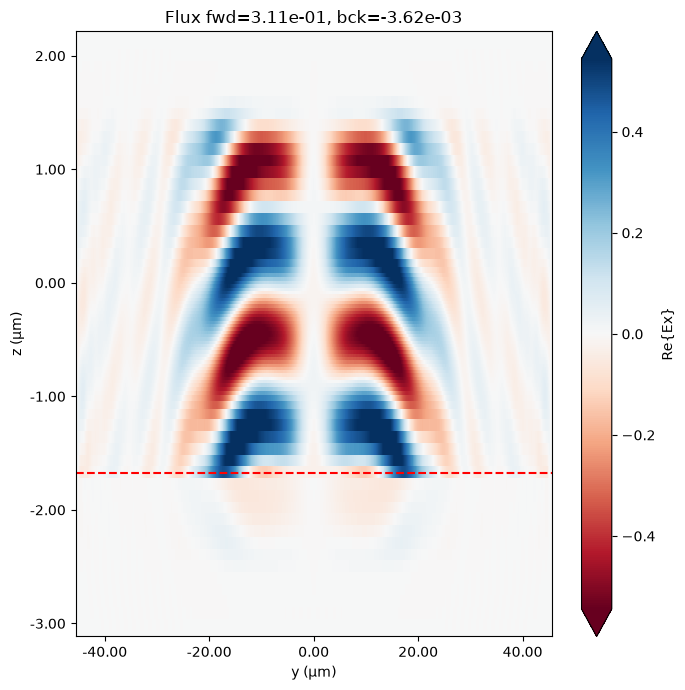

Forward flux (normalization): 3.11e-01
Backward flux (normalization): -3.62e-03


In [133]:
#plot the yz monitor to observe source directionality
#plot the flux to observe source directionality
sim_norm_2_data = SimulationData.from_file(fname="full_meta_results/full_meta2_normalization.hdf5")
fig, ax = plt.subplots(1)

sim_norm_2_data.plot_field("field_yz", field_name="Ex", val="real", ax=ax)

ax.set_title(
    f"Flux fwd={float(sim_norm_2_data['transmittance_flux_monitor_2'].flux.item()):1.2e}, bck={float(sim_norm_2_data['reflectance_flux_monitor_2'].flux.item()):1.2e}"
)
print(source_position_2)
ax.axhline(source_position_2, color='red', linestyle='--', linewidth = 1.5)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
forward_flux_norm_2 = float(sim_norm_2_data['transmittance_flux_monitor_2'].flux.item())  
backward_flux_norm_2 = float(sim_norm_2_data['reflectance_flux_monitor_2'].flux.item())
print(f"Forward flux (normalization): {forward_flux_norm_2:1.2e}")
print(f"Backward flux (normalization): {backward_flux_norm_2:1.2e}")

17:36:34 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

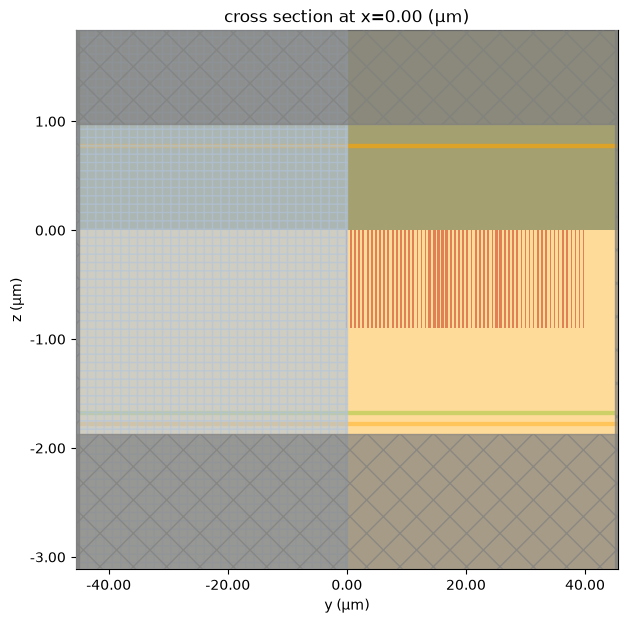

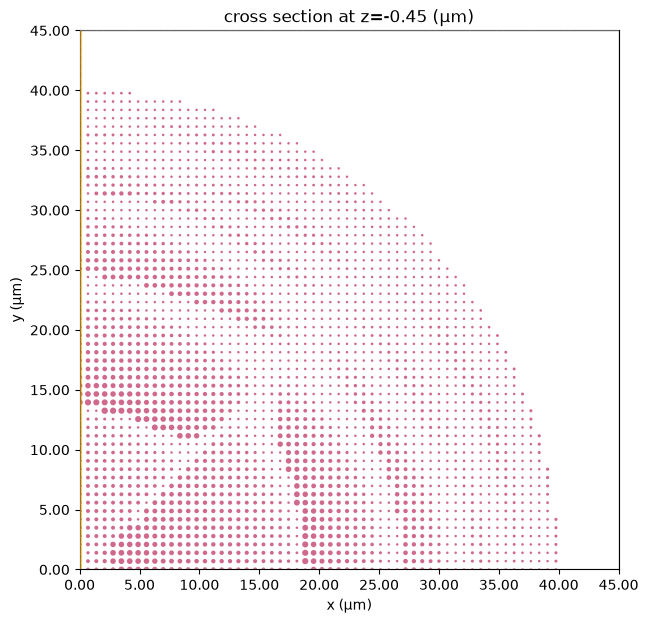

In [134]:
sim2 = td.Simulation(
    center=[0, 0, -h/2],
    size=[Lx, Ly, Lz],
    grid_spec=grid_spec_2,
    structures=[substrate_above, pillars_mask_2],
    sources=[custom_src_2],
    monitors=[reflectance_flux_monitor_2, transmittance_flux_monitor_2, monitor_proj_output_field, mnt_yz],
    run_time=run_time,
    boundary_spec=td.BoundarySpec(x=td.Boundary.pml(), y=td.Boundary.pml(), z=td.Boundary.pml()),
    symmetry=[-1,1,0],
)

fig, ax = plt.subplots()
sim2.plot(x=0, ax=ax,)
ax.set_aspect('auto')
plt.show()

fig, ax = plt.subplots()
sim2.plot(z=-h/2, ax=ax, rasterized=True)
plt.xlim(0,Lx/2)
plt.ylim(0,Ly/2)
plt.show()

In [135]:
# job = web.Job(simulation=sim2, task_name="full_meta2")
# estimated_cost = web.estimate_cost(job.task_id)

In [136]:
#sim_data_2 = job.run(path="full_meta_results/full_meta2.hdf5")

17:38:19 CEST WARNING: Override structures take no effect along x-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

              WARNING: Override structures take no effect along y-axis. If      
              intending to apply override structures to this axis, use          
              'AutoGrid' or 'QuasiUniformGrid'.                                 

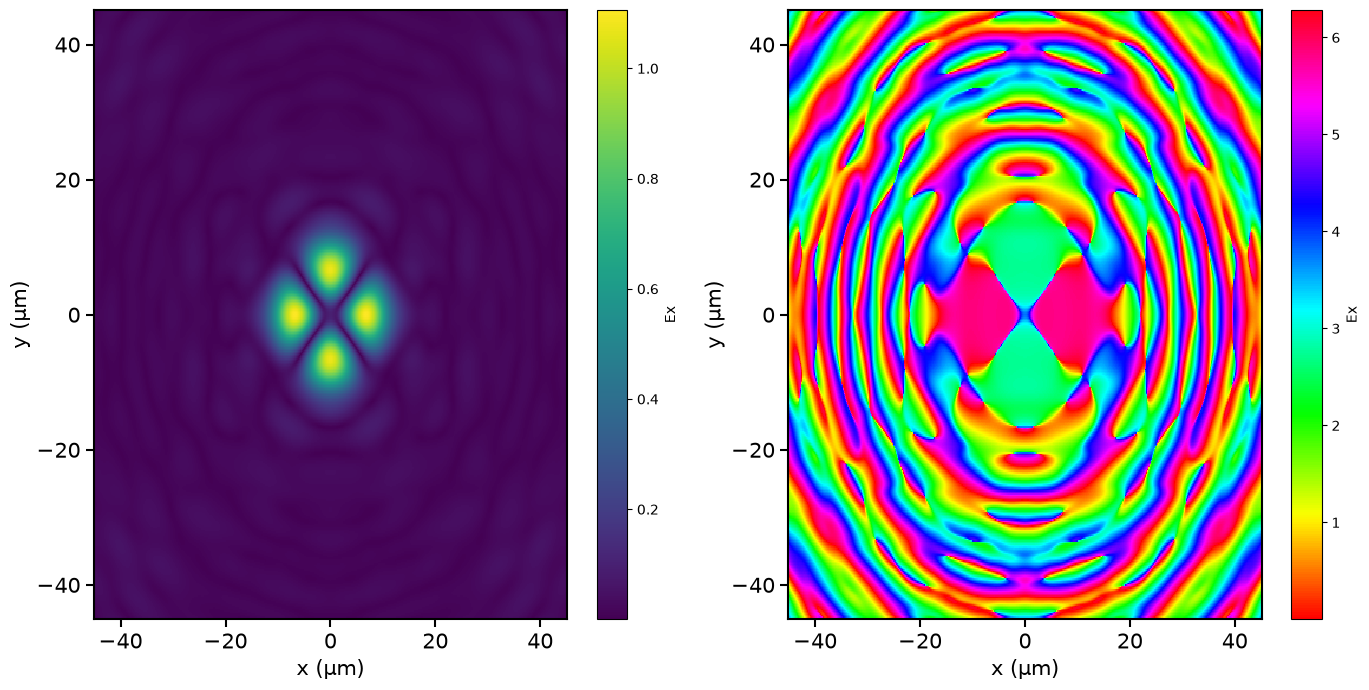

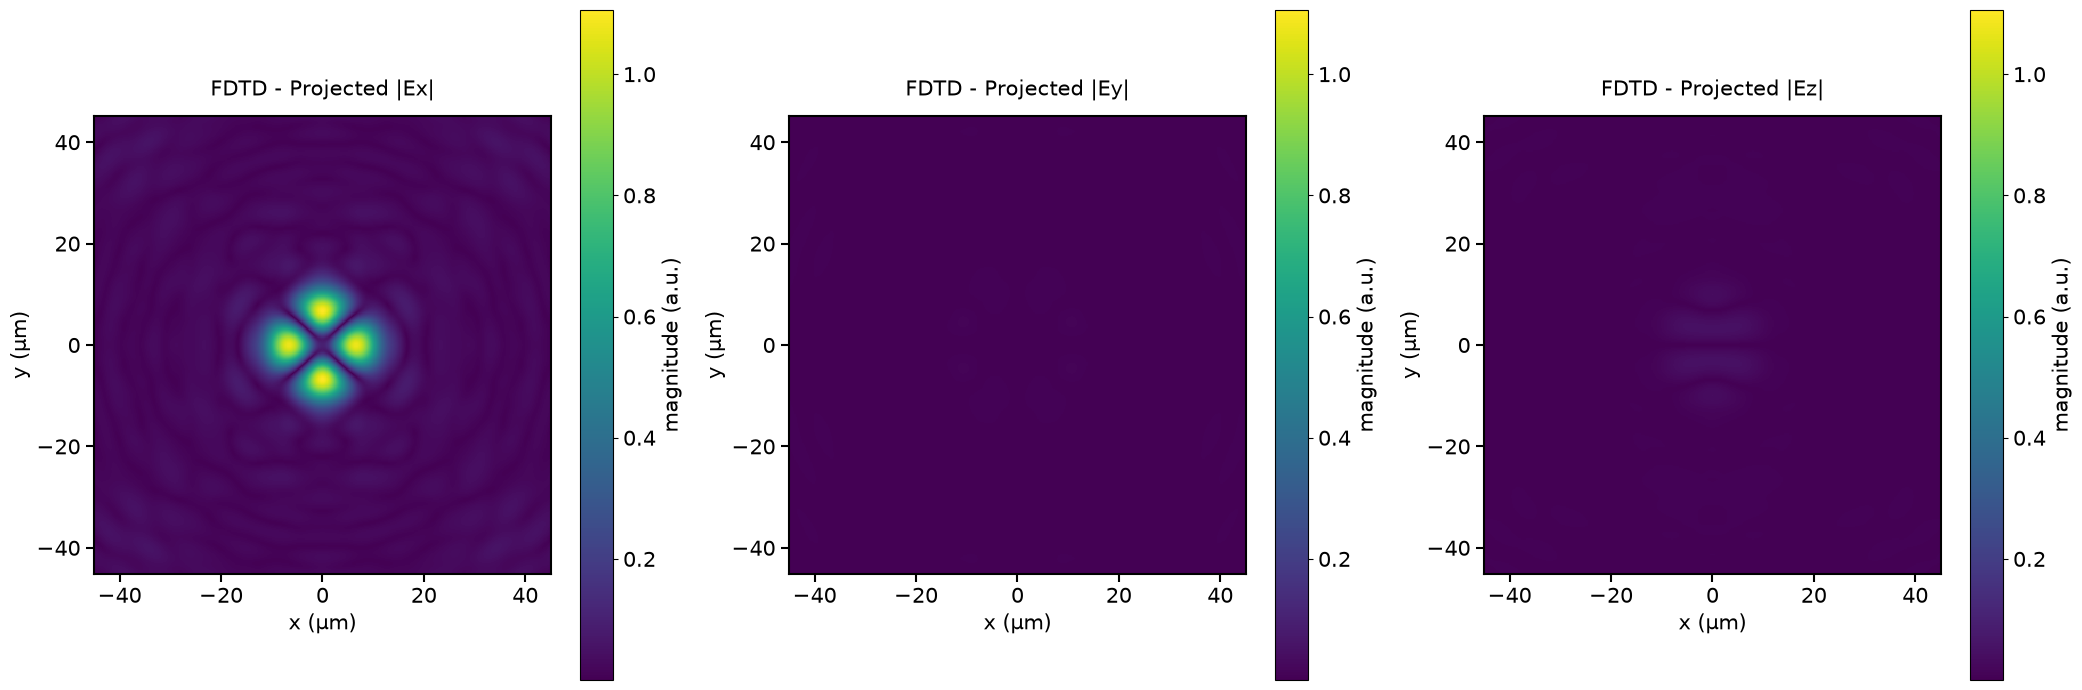

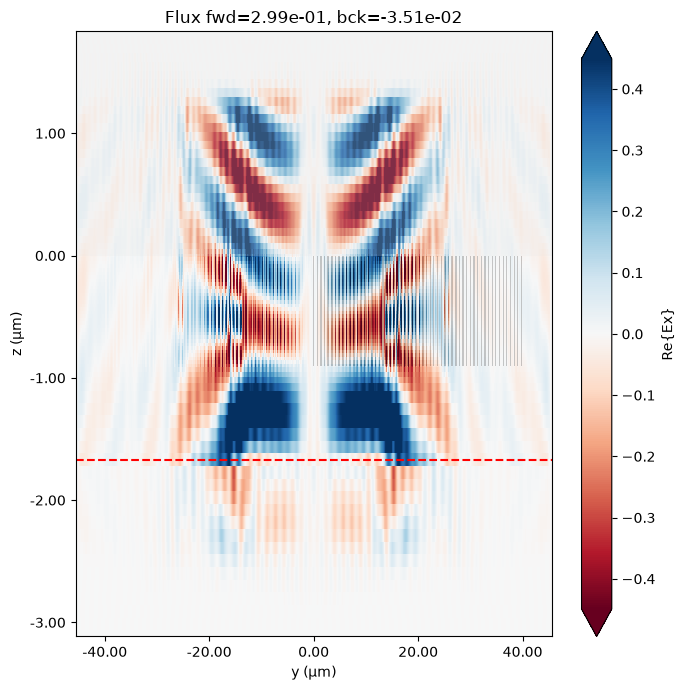

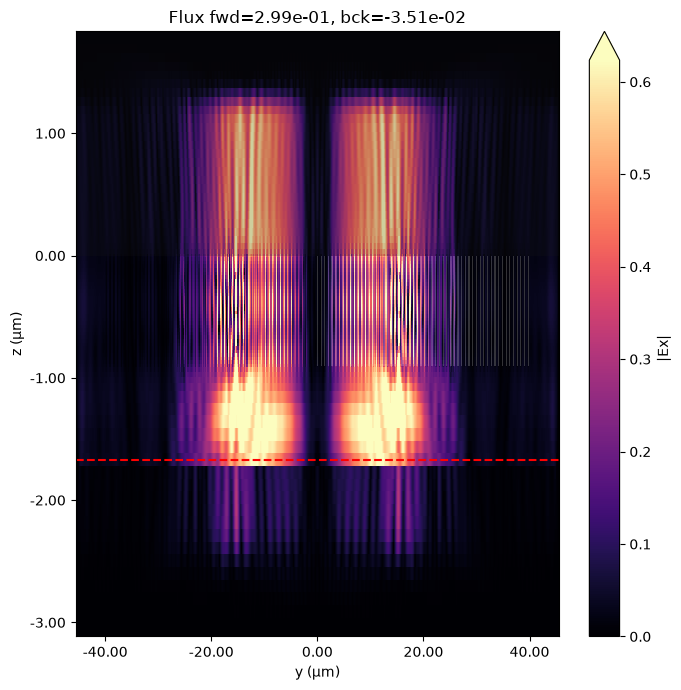

Forward flux (raw): 2.99e-01
Backward flux (raw): -3.51e-02
Forward flux (comp): 9.62e-01


In [139]:
sim_data_2 = SimulationData.from_file(fname="full_meta_results/full_meta2.hdf5")
proj_fields_2 = sim_data_2["ff_proj_monitor_output_field"].fields_cartesian.Ex.sel(f=freq0, z=projection_distance_output_field)
np.save("full_meta_results/full_meta2_proj_fields.npy", proj_fields_2)

proj_Ex_field_2 = sim_data_2["ff_proj_monitor_output_field"].fields_cartesian.Ex.sel(f=freq0, z=projection_distance_output_field)
proj_Ey_field_2 = sim_data_2["ff_proj_monitor_output_field"].fields_cartesian.Ey.sel(f=freq0, z=projection_distance_output_field)
proj_Ez_field_2 = sim_data_2["ff_proj_monitor_output_field"].fields_cartesian.Ez.sel(f=freq0, z=projection_distance_output_field)

fig, ax = plt.subplots(1,2,figsize=(14, 7))
np.abs(proj_Ex_field_2).plot(ax=ax[0], x = 'x', y = 'y', rasterized = True)

phase_Ex_field_2 = proj_Ex_field_2.copy(
    data=np.mod(np.angle(proj_Ex_field_2.data), 2 * np.pi)
)
phase_Ex_field_2.plot(ax=ax[1], x = 'x', y = 'y', cmap='hsv', rasterized = True)
ax[0].set_title("")
ax[0].set_xlabel("x (μm)", fontsize=15)
ax[0].set_ylabel("y (μm)", fontsize=15)
ax[1].set_title("")
ax[1].set_xlabel("x (μm)", fontsize=15)
ax[1].set_ylabel("y (μm)", fontsize=15)
for ax_item in ax:
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
ax[0].set_aspect('auto')
ax[1].set_aspect('auto')
plt.tight_layout()
plt.savefig("full_meta_results/plots/full_meta2_proj_fields.pdf", bbox_inches='tight', dpi=300)

#change the following plots to display the quantities on the same scale as the Ex component
fig, ax = plt.subplots(1,3,figsize=(21, 7))
im0 = ax[0].pcolormesh(X_far, Y_far, np.abs(proj_Ex_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[0].set_title("FDTD - Projected |Ex|", fontsize=15, pad=15)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("y (μm)", fontsize=15,)
ax[0].set_aspect('equal')
cbar0 = plt.colorbar(im0, ax=ax[0], label="magnitude (a.u.)")
cbar0.set_label("magnitude (a.u.)", fontsize=15)
cbar0.ax.tick_params(labelsize=15)

im1 = ax[1].pcolormesh(X_far, Y_far, np.abs(proj_Ey_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[1].set_title("FDTD - Projected |Ey|", fontsize=15, pad=15)
ax[1].set_xlabel("x (μm)", fontsize=15,)
ax[1].set_ylabel("y (μm)", fontsize=15,)
ax[1].set_aspect('equal')
cbar1 = plt.colorbar(im1, ax=ax[1], label="magnitude (a.u.)")
cbar1.set_label("magnitude (a.u.)", fontsize=15)
cbar1.ax.tick_params(labelsize=15)

im2 = ax[2].pcolormesh(X_far, Y_far, np.abs(proj_Ez_field_2), shading='auto', cmap='viridis',rasterized=True, vmax = np.abs(proj_Ex_field_2).max(), vmin = np.abs(proj_Ex_field_2).min())
ax[2].set_title("FDTD - Projected |Ez|", fontsize=15, pad=15)
ax[2].set_xlabel("x (μm)", fontsize=15,)
ax[2].set_ylabel("y (μm)", fontsize=15,)
ax[2].set_aspect('equal')
cbar2 = plt.colorbar(im2, ax=ax[2], label="magnitude (a.u.)")
cbar2.set_label("magnitude (a.u.)", fontsize=15)
cbar2.ax.tick_params(labelsize=15)

for ax_item in ax:
    ax_item.title.set_fontsize(15)
    ax_item.xaxis.label.set_fontsize(15)
    ax_item.yaxis.label.set_fontsize(15)
    ax_item.tick_params(labelsize=15, width=1.5, length=6)
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)
plt.tight_layout()
plt.show()
#plt.savefig("full_meta_results/full_meta2_proj_E_field_intensity.pdf", bbox_inches='tight', dpi=300)

#plot the real part of the Ex field on the yz plane
fig, ax = plt.subplots(1)
sim_data_2.plot_field("field_yz", field_name="Ex", val="real", ax=ax)
ax.set_title(
    f"Flux fwd={float(sim_data_2['transmittance_flux_monitor_2'].flux.item()):1.2e}, bck={float(sim_data_2['reflectance_flux_monitor_2'].flux.item()):1.2e}"
)
ax.axhline(source_position_2, color='red', linestyle='--', linewidth=1.5)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()

#plot the flux to observe source directionality
#add a red line at the source position
fig, ax = plt.subplots(1)
sim_data_2.plot_field("field_yz", field_name="Ex", val="abs", ax=ax)
ax.set_title(
    f"Flux fwd={float(sim_data_2['transmittance_flux_monitor_2'].flux.item()):1.2e}, bck={float(sim_data_2['reflectance_flux_monitor_2'].flux.item()):1.2e}"
)
ax.axhline(source_position_2, color='red', linestyle='--', linewidth=1.5)
ax.set_aspect('auto')
plt.tight_layout()
plt.show()
forward_flux_raw_2 = float(sim_data_2['transmittance_flux_monitor_2'].flux.item())  
backward_flux_raw_2 = float(sim_data_2['reflectance_flux_monitor_2'].flux.item())
print(f"Forward flux (raw): {forward_flux_raw_2:1.2e}")
print(f"Backward flux (raw): {backward_flux_raw_2:1.2e}")

forward_flux_2_comp = forward_flux_raw_2 / forward_flux_norm_2
print(f"Forward flux (comp): {forward_flux_2_comp:1.2e}")

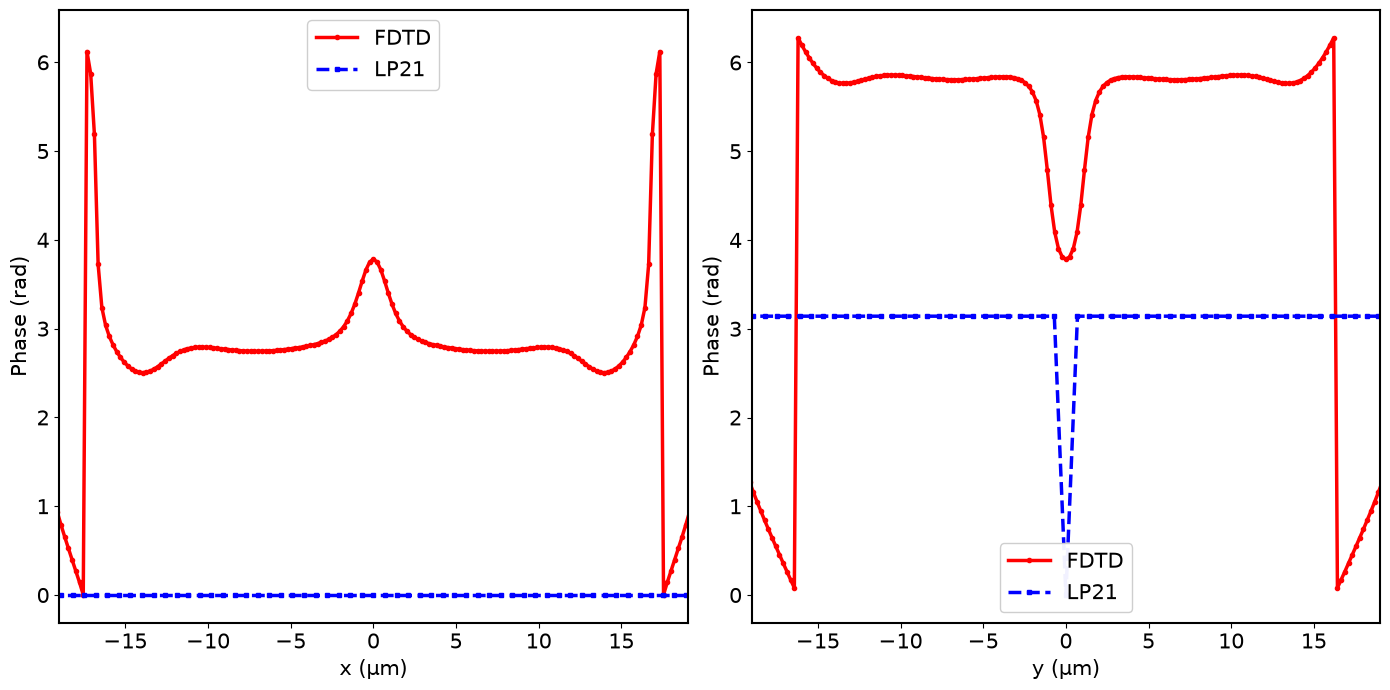

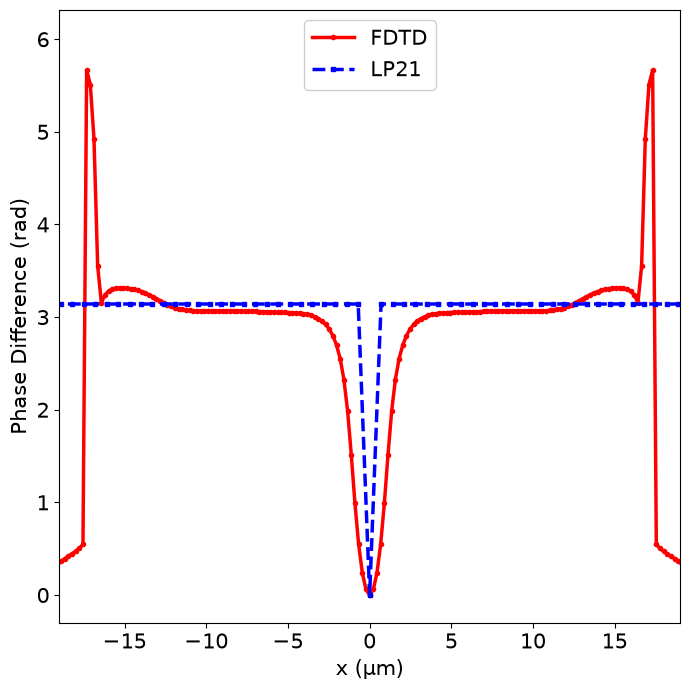

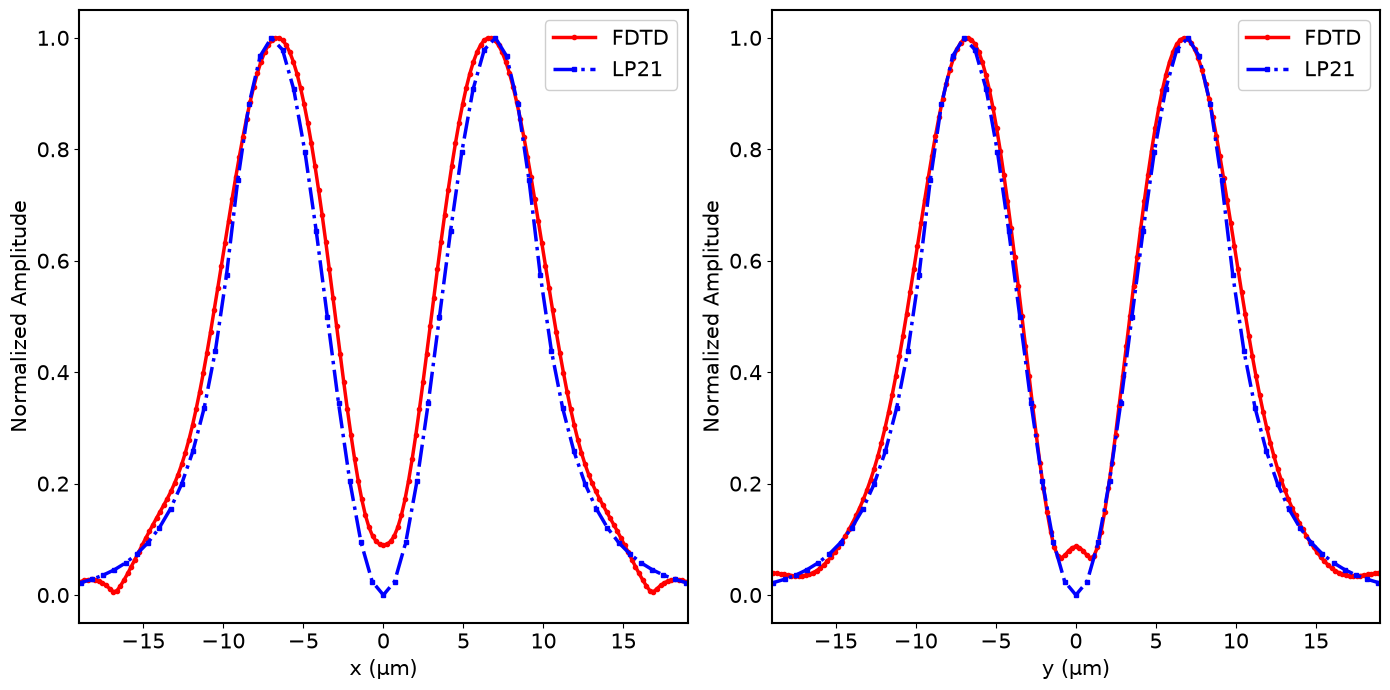

In [138]:
#import target output fields
target_output_field = np.load("full_meta_data/target_field/FMF_LP21_field_distribution_lda_1550_N_1025.npy")
output_fiber_core_diameter = 19
#make a 1D slice to compare phase of projected and target fields
#phase
projected_field_MS2_slice_x = proj_fields_2.x
projected_field_MS2_slice_xCut = proj_fields_2[X_far.shape[0]//2, :]
projected_field_MS2_slice_y = proj_fields_2.y
projected_field_MS2_slice_yCut = proj_fields_2[:,Y_far.shape[0]//2]

target_output_field_slice_xCut = target_output_field[X.shape[0]//2,:]
target_output_field_slice_x = X[X.shape[0]//2,:]
target_output_field_slice_yCut = target_output_field[:,Y.shape[0]//2]
target_output_field_slice_y = Y[:,Y.shape[0]//2]

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(projected_field_MS2_slice_x, (np.angle(projected_field_MS2_slice_xCut)+2*np.pi)%(2*np.pi),
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[0].plot(target_output_field_slice_x, (np.angle(target_output_field_slice_xCut)+2*np.pi)%(2*np.pi),
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("Phase (rad)", fontsize=15,)
ax[0].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[0].tick_params(labelsize=15)
ax[0].legend(fontsize=15, loc='best', framealpha=0.95)


ax[1].plot(projected_field_MS2_slice_y, (np.angle(projected_field_MS2_slice_yCut)+2*np.pi)%(2*np.pi),
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[1].plot(target_output_field_slice_y, (np.angle(target_output_field_slice_yCut)+2*np.pi)%(2*np.pi),
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[1].set_xlabel("y (μm)", fontsize=15,)
ax[1].set_ylabel("Phase (rad)", fontsize=15,)
ax[1].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[1].tick_params(labelsize=15)
ax[1].legend(fontsize=15, loc='best', framealpha=0.95)


for ax_item in ax:
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()
#plt.savefig("full_meta_results/fdtd_vs_target_output_field_phase.pdf")
plt.close()

#relative phase difference between x and y spatial slices for both FDTD and target fields
fig, ax = plt.subplots(figsize=(7, 7))
fdtd_phase_diff = np.abs((np.angle(projected_field_MS2_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(projected_field_MS2_slice_yCut)+2*np.pi)%(2*np.pi))
target_phase_diff = np.abs((np.angle(target_output_field_slice_xCut)+2*np.pi)%(2*np.pi) - (np.angle(target_output_field_slice_yCut)+2*np.pi)%(2*np.pi))
ax.plot(projected_field_MS2_slice_x, fdtd_phase_diff,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax.plot(target_output_field_slice_x, target_phase_diff,
           '--b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax.set_xlabel("x (μm)", fontsize=15,)
ax.set_ylabel("Phase Difference (rad)", fontsize=15,)
ax.set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax.tick_params(labelsize=15)
ax.legend(fontsize=15, loc='best', framealpha=0.95)
plt.tight_layout()
plt.show()
#plt.savefig("full_meta_results/differential_output_field_phase.pdf")
plt.close()

#amplitudes
normalized_projected_field_MS2_xCut = np.abs(projected_field_MS2_slice_xCut) / np.max(np.abs(projected_field_MS2_slice_xCut))
normalized_target_output_field_xCut = np.abs(target_output_field_slice_xCut) / np.max(np.abs(target_output_field_slice_xCut))
normalized_projected_field_MS2_yCut = np.abs(projected_field_MS2_slice_yCut) / np.max(np.abs(projected_field_MS2_slice_yCut))
normalized_target_output_field_yCut = np.abs(target_output_field_slice_yCut) / np.max(np.abs(target_output_field_slice_yCut))

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].plot(projected_field_MS2_slice_x, normalized_projected_field_MS2_xCut,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[0].plot(target_output_field_slice_x, normalized_target_output_field_xCut,
           '-.b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[0].set_xlabel("x (μm)", fontsize=15,)
ax[0].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[0].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[0].tick_params(labelsize=15)
ax[0].legend(fontsize=15, loc='best', framealpha=0.95)


ax[1].plot(projected_field_MS2_slice_y, normalized_projected_field_MS2_yCut,
           'r', label="FDTD", linewidth=2.5, marker='o', markersize=3,)
ax[1].plot(target_output_field_slice_y, normalized_target_output_field_yCut,
           '-.b', label="LP21", linewidth=2.5, marker='s', markersize=3,)
ax[1].set_xlabel("y (μm)", fontsize=15,)
ax[1].set_ylabel("Normalized Amplitude", fontsize=15,)
ax[1].set_xlim([-output_fiber_core_diameter, output_fiber_core_diameter])
ax[1].tick_params(labelsize=15)
ax[1].legend(fontsize=15, loc='best', framealpha=0.95)


for ax_item in ax:
    for spine in ax_item.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()
#plt.savefig("full_meta_results/fdtd_vs_target_output_field_normalized_amplitude.pdf")